# EDA: фьючерсы на курс юань/рубль (серия `CR`, MOEX FORTS), 10-минутные свечи

**Проект:** Торговая система на основе прогнозирования фьючерсов (годовой проект, ВШЭ)
**Команда:** Коваленок Анна, Шапорова Екатерина, Коннов Михаил · **Куратор:** Дмитрий Янышев

**Объект исследования.** Квартальные фьючерсы `CRH*/CRM*/CRU*/CRZ*` на курс CNY/RUB (лот 1000 юаней, цена в рублях за 1 юань, шаг цены 0,001), 10-минутные свечи MOEX ISS, апрель 2022 — ноябрь 2026, 19 контрактов.

**Структура ноутбука (соответствует пунктам задания)**

| Раздел | Задание |
|---|---|
| 1. Источник данных и загрузка | — |
| 2. EDA по каждому фьючерсному контракту | п. 1 |
| 3. Единый временной ряд: front-contract и roll-корректировка | п. 2 |
| 4. Логарифмические доходности непрерывного ряда | п. 3 |
| 5. Целевая переменная и признаки | п. 3 |
| 6. Метрики качества и baseline | пп. 4–5 |
| 7. Итоговые выводы и рекомендации | — |
| 8. Сохранение результатов | — |

Все промежуточные выводы оформлены отдельными ячейками «Вывод». Числа в выводах соответствуют выводу кода при полном перезапуске ноутбука (`Restart & Run All`).

## 0. Настройка окружения

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import requests
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", message=".*encountered in matmul")   # ложные предупреждения numpy/Accelerate на macOS
warnings.filterwarnings("ignore", message=".*OpenSSL.*")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")

/Users/mishanya/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
# Единый стиль графиков: светлая поверхность, тонкие линии, приглушённая сетка,
# фиксированный порядок категориальных цветов, одна ось Y на график.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MUTED = "#898781"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=PALETTE),
    "lines.linewidth": 1.5, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False, "figure.dpi": 100,
})

In [3]:
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"
for d in (RAW_DIR, PROCESSED_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RAW_FILE = RAW_DIR / "cnyrub_futures_CR_10m_all.csv"

# False -> читаем сохранённую выгрузку; True -> заново качаем всё из MOEX ISS (~5-10 минут)
DOWNLOAD_FROM_MOEX = False
DATE_FROM, DATE_TO = "2022-01-01", "2026-11-08"

## 1. Источник данных и загрузка

Данные получены через публичный API MOEX ISS: `https://iss.moex.com/iss/engines/futures/markets/forts/securities/{ticker}/candles.json`, `interval=10`.

**Что выяснили при изучении API (на примере `CRZ3`):**
- API отдаёт **не более 500 строк за запрос** (запрос годовой истории вернул ровно 500 строк) → нужна пагинация через параметр `start`. После неё по `CRZ3` за 2023 год получено 12 852 свечи (3 янв — 21 дек 2023).
- Свеча формируется **только для интервалов, в которых были сделки**, поэтому сетка времени нерегулярна: на тестовом фрагменте 3–5 января 2023 г. лишь 45% внутридневных шагов равны 10 минутам, на всей истории `CRZ3` — 92,6%. Разница объясняется жизненным циклом ликвидности (раздел 2.3).
- Поле `value` (оборот в рублях) в свечах фьючерсов **всегда равно 0** → неинформативно, исключаем из признаков. Оборот в деньгах есть только в дневном архиве `history` (`VALUE`).
- Контракт `CRH2` в истории отсутствует; первый доступный — `CRM2` (торги с 21.04.2022).
- Последний торговый день квартального контракта — **третий четверг месяца исполнения** (H — март, M — июнь, U — сентябрь, Z — декабрь); последняя 10-минутная свеча — 13:50. Для 18 истёкших контрактов это совпало с архивом MOEX `history` во всех 18 случаях.

In [4]:
def download_futures_candles_10m(ticker, date_from, date_to):
    # Полная выгрузка 10-минутных свечей одного контракта с пагинацией по 500 строк.
    url = f"https://iss.moex.com/iss/engines/futures/markets/forts/securities/{ticker}/candles.json"
    all_rows, start, columns = [], 0, None
    while True:
        params = {"from": date_from, "till": date_to, "interval": 10, "iss.meta": "off", "start": start}
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()
        data = response.json()["candles"]
        columns, rows = data["columns"], data["data"]
        if not rows:
            break
        all_rows.extend(rows)
        start += len(rows)
    df = pd.DataFrame(all_rows, columns=columns)
    if not df.empty:
        df["ticker"] = ticker
        df["begin"] = pd.to_datetime(df["begin"])
        df["end"] = pd.to_datetime(df["end"])
    return df


def get_last_trade_date(ticker, approximate_last_date):
    # Последняя торговая дата контракта по дневному архиву MOEX (для сверки дат экспирации).
    url = f"https://iss.moex.com/iss/history/engines/futures/markets/forts/securities/{ticker}.json"
    approx = pd.to_datetime(approximate_last_date)
    params = {"from": (approx - pd.Timedelta(days=10)).strftime("%Y-%m-%d"),
              "till": (approx + pd.Timedelta(days=10)).strftime("%Y-%m-%d"), "iss.meta": "off"}
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    hist = response.json()["history"]
    if not hist["data"]:
        return pd.NaT
    return pd.to_datetime(pd.DataFrame(hist["data"], columns=hist["columns"])["TRADEDATE"]).max()

In [5]:
MONTH_CODES = {"H": 3, "M": 6, "U": 9, "Z": 12}


def contract_expiry(ticker):
    # Последний торговый день: третий четверг месяца исполнения (CRZ3 -> 2023-12-21).
    year, month = 2020 + int(ticker[3]), MONTH_CODES[ticker[2]]
    first_day = pd.Timestamp(year, month, 1)
    return first_day + pd.Timedelta(days=(3 - first_day.dayofweek) % 7 + 14)


if DOWNLOAD_FROM_MOEX or not RAW_FILE.exists():
    tickers = [f"CR{q}{y}" for y in range(2, 7) for q in "HMUZ"]
    parts = []
    for ticker in tickers:
        df = download_futures_candles_10m(ticker, DATE_FROM, DATE_TO)
        print(f"{ticker}: {'данных нет' if df.empty else f'{len(df)} строк'}")
        if not df.empty:
            df.to_csv(RAW_DIR / f"{ticker}_10m.csv", index=False)
            parts.append(df)
    raw_all_10m = pd.concat(parts, ignore_index=True).sort_values(["begin", "ticker"]).reset_index(drop=True)
    raw_all_10m.to_csv(RAW_FILE, index=False)
else:
    raw_all_10m = pd.read_csv(RAW_FILE, parse_dates=["begin", "end"])

contract_order = sorted(raw_all_10m["ticker"].unique(), key=contract_expiry)
expiry = pd.Series({t: contract_expiry(t) for t in contract_order}, name="expiry")
DATA_END = raw_all_10m["begin"].max()

print("Размер:", raw_all_10m.shape)
print("Контрактов:", len(contract_order), "->", ", ".join(contract_order))
print("Период:", raw_all_10m["begin"].min(), "—", DATA_END)

Размер: (247373, 9)
Контрактов: 19 -> CRM2, CRU2, CRZ2, CRH3, CRM3, CRU3, CRZ3, CRH4, CRM4, CRU4, CRZ4, CRH5, CRM5, CRU5, CRZ5, CRH6, CRM6, CRU6, CRZ6
Период: 2022-04-21 10:00:00 — 2026-11-08 18:50:00


In [6]:
# Проверка: последняя свеча каждого истёкшего контракта приходится на третий четверг месяца исполнения
last_obs = raw_all_10m.groupby("ticker")["begin"].max().dt.normalize()
expiry_check = pd.DataFrame({"last_observation": last_obs, "expiry_rule": expiry}).loc[contract_order]
expiry_check["expired"] = expiry_check["expiry_rule"] <= DATA_END
expiry_check["match"] = expiry_check["last_observation"] == expiry_check["expiry_rule"]
print("Истёкших контрактов:", expiry_check["expired"].sum(),
      "| совпадений с правилом третьего четверга:", expiry_check.loc[expiry_check["expired"], "match"].sum())
expiry_check.tail(3)

Истёкших контрактов: 18 | совпадений с правилом третьего четверга: 18


,last_observation,expiry_rule,expired,match
CRM6,2026-06-18,2026-06-18,True,True
CRU6,2026-09-17,2026-09-17,True,True
CRZ6,2026-11-08,2026-12-17,False,False


**Вывод.** Даты экспирации 18 истёкших контрактов полностью совпадают с правилом «третий четверг месяца исполнения» (и с архивом MOEX). Текущий контракт `CRZ6` исполняется 17.12.2026, данные по нему выгружены до 08.11.2026.

Расхождение `CRZ6` с архивом в старой версии (последняя свеча 08.11 против архивной даты 06.11) — не ошибка данных: 08.11.2026 — воскресенье, это свечи **торговой сессии выходного дня**, которые в дневном архиве MOEX относятся к другой торговой дате.

## 2. EDA по каждому фьючерсному контракту (задание 1)

Все контракты серии `CR` — это один и тот же базовый актив (курс CNY/RUB) с разными датами исполнения, и в любой момент одновременно торгуются 4–6 контрактов. Поэтому EDA по контрактам отвечает на вопросы, от которых зависят следующие шаги:

1. насколько качественны и полны данные каждого контракта;
2. когда контракт ликвиден и **когда нужно переключаться** на следующий (основа для п. 2);
3. чем различаются цены контрактов (контанго, roll gaps);
4. одинаковы ли статистические свойства доходностей в разных контрактах (если да, свойства склеенного ряда — не артефакт склейки).

Вспомогательные поля: `expiry` — дата исполнения, `days_to_expiry` — календарных дней до исполнения, `is_nearest` — контракт является ближайшим (не истёкшим) на эту дату.

In [7]:
raw = raw_all_10m.sort_values(["ticker", "begin"]).reset_index(drop=True).copy()
raw["date"] = raw["begin"].dt.normalize()
raw["expiry"] = raw["ticker"].map(expiry)
raw["days_to_expiry"] = (raw["expiry"] - raw["date"]).dt.days

# Ближайший и следующий контракт на каждую дату
exp_values = expiry.to_numpy()
pos = np.searchsorted(exp_values, raw["date"].to_numpy(), side="left")
raw["nearest"] = expiry.index.to_numpy()[pos]
raw["next"] = np.where(pos + 1 < len(expiry), expiry.index.to_numpy()[np.minimum(pos + 1, len(expiry) - 1)], None)
raw["is_nearest"] = raw["ticker"] == raw["nearest"]

# Доходность внутри одного контракта (без склейки) и шаг времени внутри дня
raw["log_ret"] = np.log(raw["close"]).groupby(raw["ticker"]).diff()
raw["intraday_gap"] = raw.groupby(["ticker", "date"])["begin"].diff()
raw["ret_10m"] = raw["log_ret"].where(raw["intraday_gap"] == pd.Timedelta(minutes=10))
raw[["begin", "ticker", "close", "volume", "days_to_expiry", "is_nearest", "log_ret", "ret_10m"]].head()

,begin,ticker,close,volume,days_to_expiry,is_nearest,log_ret,ret_10m
0,2022-08-15 13:40:00,CRH3,10.16,1,213,False,NaN,NaN
1,2022-08-16 12:20:00,CRH3,9.86,1,212,False,-0.0299723,NaN
2,2022-08-16 14:40:00,CRH3,10,2,212,False,0.0140989,NaN
3,2022-08-17 10:00:00,CRH3,9.93,1,211,False,-0.00702461,NaN
4,2022-08-18 13:10:00,CRH3,9.65,1,210,False,-0.0286026,NaN


### 2.1 Паспорт контрактов

In [8]:
g = raw.groupby("ticker")
passport = pd.DataFrame({
    "first_candle": g["begin"].min(),
    "last_candle": g["begin"].max(),
    "expiry": expiry,
    "candles": g.size(),
    "trading_days": g["date"].nunique(),
    "candles_as_nearest": raw[raw["is_nearest"]].groupby("ticker").size(),
    "total_volume_mln": g["volume"].sum() / 1e6,
    "volume_share_as_nearest": raw[raw["is_nearest"]].groupby("ticker")["volume"].sum() / g["volume"].sum(),
    "median_volume_per_candle": g["volume"].median(),
    "price_min": g["low"].min(),
    "price_max": g["high"].max(),
    "zero_return_share": g["log_ret"].apply(lambda x: (x.dropna() == 0).mean()),
    "weekend_candles": g["begin"].apply(lambda x: (x.dt.dayofweek >= 5).sum()),
}).loc[contract_order]
passport["life_days"] = (passport["last_candle"] - passport["first_candle"]).dt.days
passport

,first_candle,last_candle,expiry,candles,trading_days,candles_as_nearest,total_volume_mln,volume_share_as_nearest,median_volume_per_candle,price_min,price_max,zero_return_share,weekend_candles,life_days
CRM2,2022-04-21 10:00:00,2022-06-16 13:50:00,2022-06-16,1656,36,1656,0.046855,1,13,8.39,12.99,0.150453,0,56
CRU2,2022-05-12 10:20:00,2022-09-15 13:50:00,2022-09-15,5270,90,4767,15.143,0.998692,827,7.78,12.05,0.294173,0,126
CRZ2,2022-06-20 14:30:00,2022-12-15 13:50:00,2022-12-15,9202,128,5570,66.2093,0.94727,"1,764",8.11,10.3,0.224323,0,177
CRH3,2022-08-15 13:40:00,2023-03-16 13:50:00,2023-03-16,10207,148,5392,121.012,0.951411,"1,868",8.3,11.184,0.095728,0,213
CRM3,2022-09-14 13:50:00,2023-06-15 13:50:00,2023-06-15,11516,189,5392,140.579,0.9468,811.5,8.6,12.195,0.0798089,0,274
CRU3,2022-11-16 14:40:00,2023-09-21 13:50:00,2023-09-21,12358,212,6119,236.435,0.97005,"1,267.5",9.1,14.046,0.0692725,0,308
CRZ3,2022-11-15 22:10:00,2023-12-21 13:50:00,2023-12-21,12962,273,5701,251.567,0.922917,"1,573.5",9.172,14.298,0.0687447,0,400
CRH4,2022-11-22 16:50:00,2024-03-21 13:50:00,2024-03-21,13147,313,5371,217.69,0.923955,794,9.7,14.628,0.0827628,0,484
CRM4,2022-12-22 13:40:00,2024-06-20 13:50:00,2024-06-20,12791,359,5513,203.451,0.909115,692,10.882,14.955,0.0982017,89,546
CRU4,2023-03-20 12:40:00,2024-09-19 13:50:00,2024-09-19,12973,350,5308,311.343,0.890855,732,11.084,14.998,0.0948196,74,549


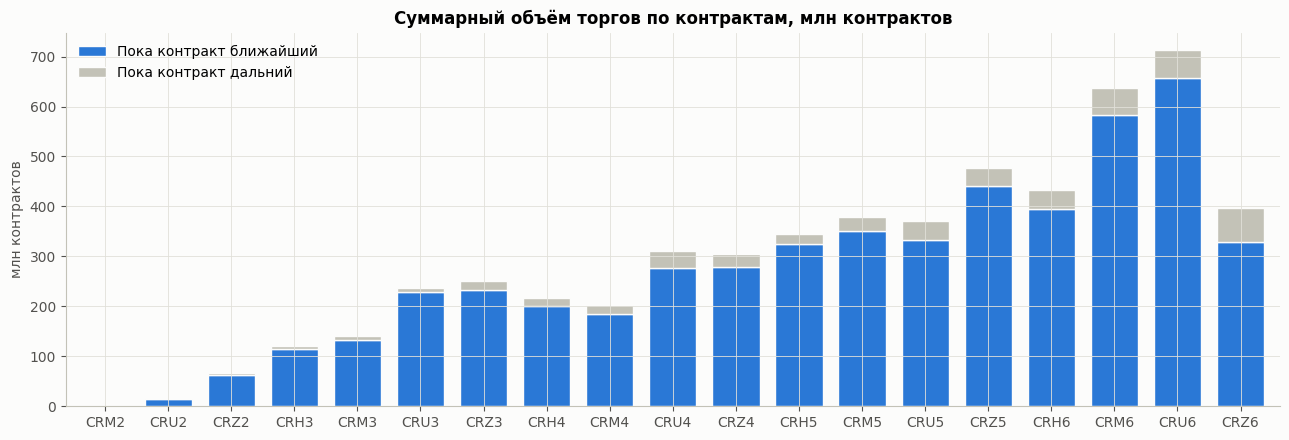

Доля объёма, наторгованного в статусе ближайшего контракта (медиана по контрактам): 92.4%


In [9]:
vol_split = pd.DataFrame({
    "Пока контракт ближайший": passport["total_volume_mln"] * passport["volume_share_as_nearest"],
    "Пока контракт дальний": passport["total_volume_mln"] * (1 - passport["volume_share_as_nearest"]),
})
ax = vol_split.plot(kind="bar", stacked=True, figsize=(13, 4.5), width=0.75,
                    color=[PALETTE[0], "#c3c2b7"], edgecolor="#fcfcfb", linewidth=1)
ax.set_title("Суммарный объём торгов по контрактам, млн контрактов")
ax.set_xlabel("")
ax.set_ylabel("млн контрактов")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Доля объёма, наторгованного в статусе ближайшего контракта (медиана по контрактам): "
      f"{passport['volume_share_as_nearest'].median():.1%}")

**Вывод по паспорту контрактов.**
- Выгружено 19 контрактов (`CRM2` … `CRZ6`), 247 373 свечи. Каждый контракт торгуется 1–1,5 года, но **основной объём (медиана ≈ 92% объёма контракта) наторгован в последний квартал жизни**, пока контракт ближайший. Дальние контракты — тонкий рынок.
- Объём торгов серии быстро рос: от 0,05 млн контрактов у `CRM2` до 0,6–0,7 млн у контрактов 2026 г. `CRM2` (весна 2022) — практически неликвидный контракт (медианный объём 13 контрактов на свечу), его данные следует рассматривать отдельно или исключать.
- У 7–10% свечей цена закрытия не меняется (`zero_return_share`; у контрактов 2022 г. — до 29%) — следствие дискретного шага цены и малых объёмов.
- С 2024 г. появляются свечи в выходные дни (рабочие субботы, затем торговые сессии выходного дня; в `CRU6`/`CRZ6` — сотни свечей). Это нужно учитывать в календарных признаках (`dayofweek`) и при расчёте временных шагов.

### 2.2 Качество данных по контрактам

In [10]:
def quality_checks(d):
    ohlc_bad = ((d["high"] < d[["open", "close"]].max(axis=1)) |
                (d["low"] > d[["open", "close"]].min(axis=1)) |
                (d["high"] < d["low"]))
    return pd.Series({
        "nan_cells": int(d[["open", "close", "high", "low", "volume", "begin"]].isna().sum().sum()),
        "duplicate_timestamps": int(d["begin"].duplicated().sum()),
        "ohlc_errors": int(ohlc_bad.sum()),
        "nonpositive_price": int((d[["open", "close", "high", "low"]] <= 0).any(axis=1).sum()),
        "zero_volume": int((d["volume"] <= 0).sum()),
        "value_nonzero": int((d["value"] != 0).sum()),
        "off_10m_grid": int((d["begin"].dt.minute % 10 != 0).sum()),
        "end_minus_begin_gt_10m": int((d["end"] - d["begin"] > pd.Timedelta(minutes=10)).sum()),
        "jumps_abs_ret_gt_2pct": int((d["log_ret"].abs() > 0.02).sum()),
    })


quality = raw.groupby("ticker")[raw.columns.drop("ticker")].apply(quality_checks).loc[contract_order]
quality

,nan_cells,duplicate_timestamps,ohlc_errors,nonpositive_price,zero_volume,value_nonzero,off_10m_grid,end_minus_begin_gt_10m,jumps_abs_ret_gt_2pct
ticker,,,,,,,,,
CRM2,0,0,0,0,0,0,0,0,20
CRU2,0,0,0,0,0,0,0,0,37
CRZ2,0,0,0,0,0,0,0,0,8
CRH3,0,0,0,0,0,0,0,0,6
CRM3,0,0,0,0,0,0,0,0,31
CRU3,0,0,0,0,0,0,0,0,11
CRZ3,0,0,0,0,0,0,0,0,53
CRH4,0,0,0,0,0,0,0,0,29
CRM4,0,0,0,0,0,0,0,0,50


In [11]:
# Крупнейшие скачки цены внутри контрактов: где и при каком объёме
big_jumps = (raw.loc[raw["log_ret"].abs() > 0.02,
                     ["begin", "ticker", "close", "log_ret", "volume", "is_nearest", "days_to_expiry"]]
             .sort_values("log_ret", key=np.abs, ascending=False))
print("Скачков |r| > 2%:", len(big_jumps), "| из них в 2022 г.:", (big_jumps["begin"].dt.year == 2022).sum(),
      "| в дальних (не ближайших) контрактах:", (~big_jumps["is_nearest"]).sum())
big_jumps.head(10)

Скачков |r| > 2%: 431 | из них в 2022 г.: 151 | в дальних (не ближайших) контрактах: 403


,begin,ticker,close,log_ret,volume,is_nearest,days_to_expiry
66790,2023-01-06 13:40:00,CRM4,11.75,-0.202402,1,False,531
109379,2022-05-12 12:00:00,CRU2,10.24,-0.162763,19,False,126
183469,2022-12-23 15:20:00,CRZ3,10.865,0.0921032,68,False,363
183401,2022-11-29 13:10:00,CRZ3,10.081,0.091449,50,False,387
183402,2022-11-29 13:20:00,CRZ3,9.204,-0.0910143,50,False,387
210407,2024-06-19 12:00:00,CRZ5,13.4,-0.0846703,2,False,547
155235,2025-03-07 18:00:00,CRU6,15.5,-0.0816692,1,False,559
196488,2023-08-29 14:00:00,CRZ4,14.999,0.0775346,20,False,478
210406,2024-06-11 11:20:00,CRZ5,14.584,0.0749417,1,False,555
183511,2023-01-09 10:10:00,CRZ3,11.799,0.0718483,213,False,346


**Вывод по качеству данных.**
- Во всех 19 контрактах нет пропущенных значений, дублей временных меток, логически некорректных OHLC-свечей, неположительных цен и свечей с нулевым объёмом. Все свечи стоят на 10-минутной сетке.
- `value` равно нулю во всех 247 373 свечах всех контрактов — поле удаляется из признаков.
- Скачки цены более 2% за одну свечу (431 случай) почти все приходятся на неликвидные дальние контракты (403 из 431): одиночные сделки по 1–20 контрактов далеко от рынка (до −20% у `CRM4` за 531 день до исполнения). Ещё одна концентрация — 2022 г. (151 случай), период становления биржевого рынка юаня. Это реальные сделки, а не ошибки формата, но **цены дальних контрактов нельзя использовать без фильтрации**, а период до осени 2022 г. статистически отличается от остальной выборки (см. 2.7).
- Отсутствующие свечи — главная особенность данных (см. 2.3): `NaN` в таблице нет, но часть 10-минутных интервалов отсутствует целиком.

### 2.3 Регулярность временной сетки и разрывы

In [12]:
def gap_stats(d):
    gaps = d["intraday_gap"].dropna()
    long_gaps = d.loc[d["intraday_gap"] > pd.Timedelta(minutes=10)]
    prev_begin = long_gaps["begin"] - long_gaps["intraday_gap"]
    clearing = (prev_begin.dt.hour == 18) & (long_gaps["begin"].dt.hour == 19)
    return pd.Series({
        "regular_10m_share": (gaps == pd.Timedelta(minutes=10)).mean(),
        "regular_share_as_nearest": (d.loc[d["is_nearest"], "intraday_gap"].dropna() == pd.Timedelta(minutes=10)).mean(),
        "regular_share_as_far": (d.loc[~d["is_nearest"], "intraday_gap"].dropna() == pd.Timedelta(minutes=10)).mean(),
        "long_gaps": len(long_gaps),
        "median_long_gap_min": long_gaps["intraday_gap"].median().total_seconds() / 60 if len(long_gaps) else np.nan,
        "evening_clearing_share": clearing.mean() if len(long_gaps) else np.nan,
    })


gap_table = raw.groupby("ticker")[raw.columns.drop("ticker")].apply(gap_stats).loc[contract_order]
gap_table

,regular_10m_share,regular_share_as_nearest,regular_share_as_far,long_gaps,median_long_gap_min,evening_clearing_share
ticker,,,,,,
CRM2,0.898765,0.898765,NaN,164,20,0
CRU2,0.954054,0.984049,0.658996,238,20,0.197479
CRZ2,0.942142,0.988376,0.870796,525,20,0.209524
CRH3,0.936077,0.987992,0.877564,643,20,0.195956
CRM3,0.932286,0.98818,0.882608,767,30,0.17601
CRU3,0.915116,0.988428,0.842381,"1,031",20,0.14452
CRZ3,0.921822,0.988644,0.868425,992,30,0.152218
CRH4,0.890993,0.988701,0.822036,"1,399",30,0.114367
CRM4,0.865991,0.988624,0.770266,"1,666",40,0.10084


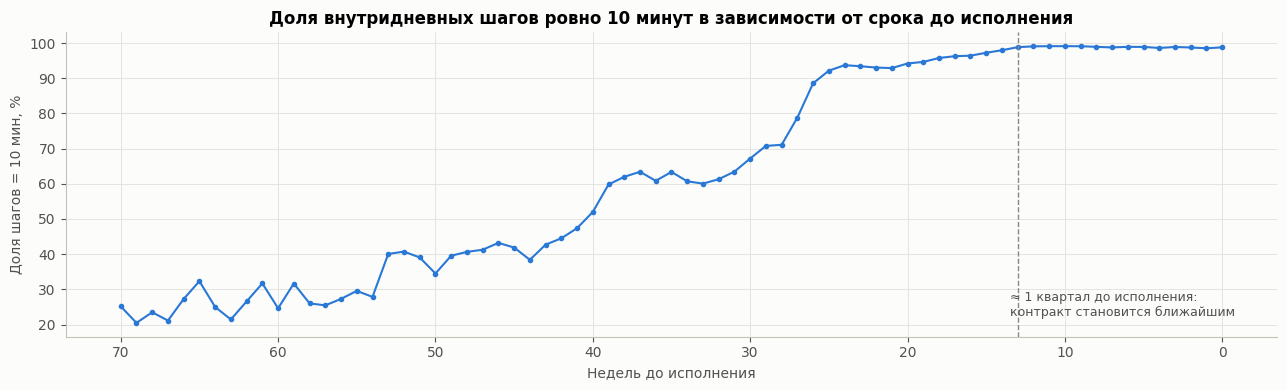

In [13]:
# Регулярность сетки в зависимости от срока до исполнения (все контракты вместе)
tmp = raw.dropna(subset=["intraday_gap"]).copy()
tmp["weeks_to_expiry"] = tmp["days_to_expiry"] // 7
reg_by_week = (tmp.groupby("weeks_to_expiry")["intraday_gap"]
               .apply(lambda x: (x == pd.Timedelta(minutes=10)).mean()))
reg_by_week = reg_by_week[reg_by_week.index <= 70]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(reg_by_week.index, reg_by_week.values * 100, color=PALETTE[0], marker="o", markersize=3)
ax.axvline(13, color=MUTED, linestyle="--", linewidth=1)
ax.text(13.5, reg_by_week.min() * 100 + 2, "≈ 1 квартал до исполнения:\nконтракт становится ближайшим", color="#52514e", fontsize=9)
ax.invert_xaxis()
ax.set_title("Доля внутридневных шагов ровно 10 минут в зависимости от срока до исполнения")
ax.set_xlabel("Недель до исполнения")
ax.set_ylabel("Доля шагов = 10 мин, %")
plt.tight_layout()
plt.show()

**Вывод по регулярности сетки.**
- Пока контракт ближайший, сетка почти регулярна: 98,8–100% внутридневных шагов равны 10 минутам (`regular_share_as_nearest`). Пока контракт дальний — только 66–88%.
- Регулярность резко растёт примерно за квартал до исполнения — ровно тогда, когда контракт становится ближайшим. Значит, **разрывы в сетке объясняются в первую очередь ликвидностью** (нет сделок → нет свечи), а не потерей данных.
- Типичный разрыв короткий (медиана 20–40 минут). Часть разрывов — структурные: вечерний клиринг (переход 18:xx → 19:xx) даёт 4–21% длинных разрывов в зависимости от контракта (у `CRZ3` — 15% из 992), остальное — межсессионные перерывы и отсутствие сделок.
- Следствие для моделирования: отсутствующие интервалы **нельзя заполнять forward fill-ом как наблюдения**; горизонт прогноза должен задаваться во времени (через 10 минут), а не в строках — так и сделано для target в разделе 5.

### 2.4 Жизненный цикл ликвидности

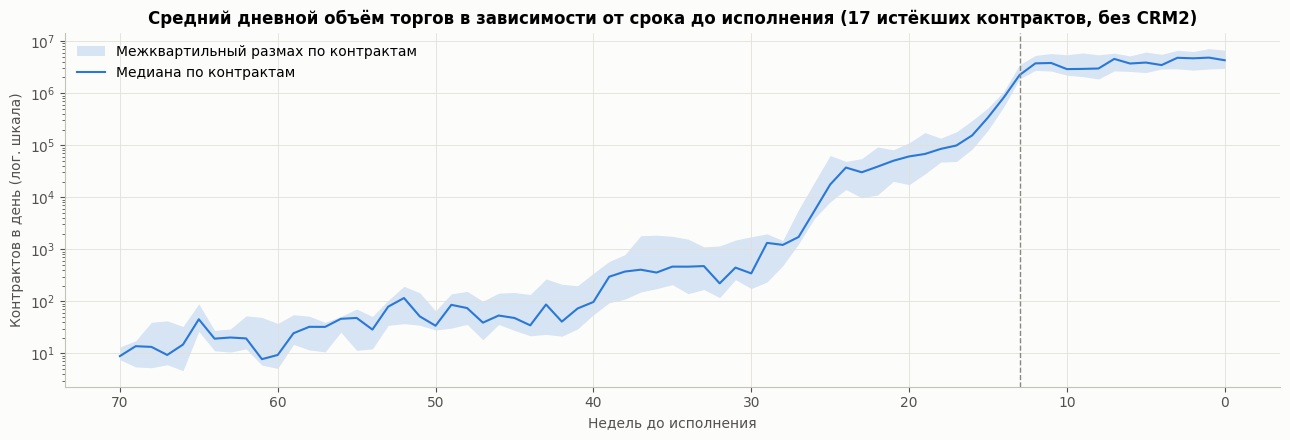

Доля объёма контракта в последние 91 день до исполнения: медиана 94.0%, min 91.2%, max 99.9%


In [14]:
daily = (raw.groupby(["ticker", "date"])
         .agg(volume=("volume", "sum"), candles=("begin", "size"), close=("close", "last"),
              days_to_expiry=("days_to_expiry", "first"), is_nearest=("is_nearest", "first"))
         .reset_index())
daily["weeks_to_expiry"] = daily["days_to_expiry"] // 7

expired = [t for t in contract_order if expiry[t] <= DATA_END and t != "CRM2"]
weekly = (daily[daily["ticker"].isin(expired)]
          .groupby(["ticker", "weeks_to_expiry"])["volume"].mean().reset_index())
profile = weekly.groupby("weeks_to_expiry")["volume"].quantile([0.25, 0.5, 0.75]).unstack()
profile = profile[profile.index <= 70]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(profile.index, profile[0.25], profile[0.75], color=PALETTE[0], alpha=0.18, linewidth=0,
                label="Межквартильный размах по контрактам")
ax.plot(profile.index, profile[0.5], color=PALETTE[0], label="Медиана по контрактам")
ax.axvline(13, color=MUTED, linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_title("Средний дневной объём торгов в зависимости от срока до исполнения (17 истёкших контрактов, без CRM2)")
ax.set_xlabel("Недель до исполнения")
ax.set_ylabel("Контрактов в день (лог. шкала)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

last_quarter_share = (daily[daily["days_to_expiry"] <= 91].groupby("ticker")["volume"].sum()
                      / daily.groupby("ticker")["volume"].sum()).loc[expired]
print(f"Доля объёма контракта в последние 91 день до исполнения: медиана {last_quarter_share.median():.1%}, "
      f"min {last_quarter_share.min():.1%}, max {last_quarter_share.max():.1%}")

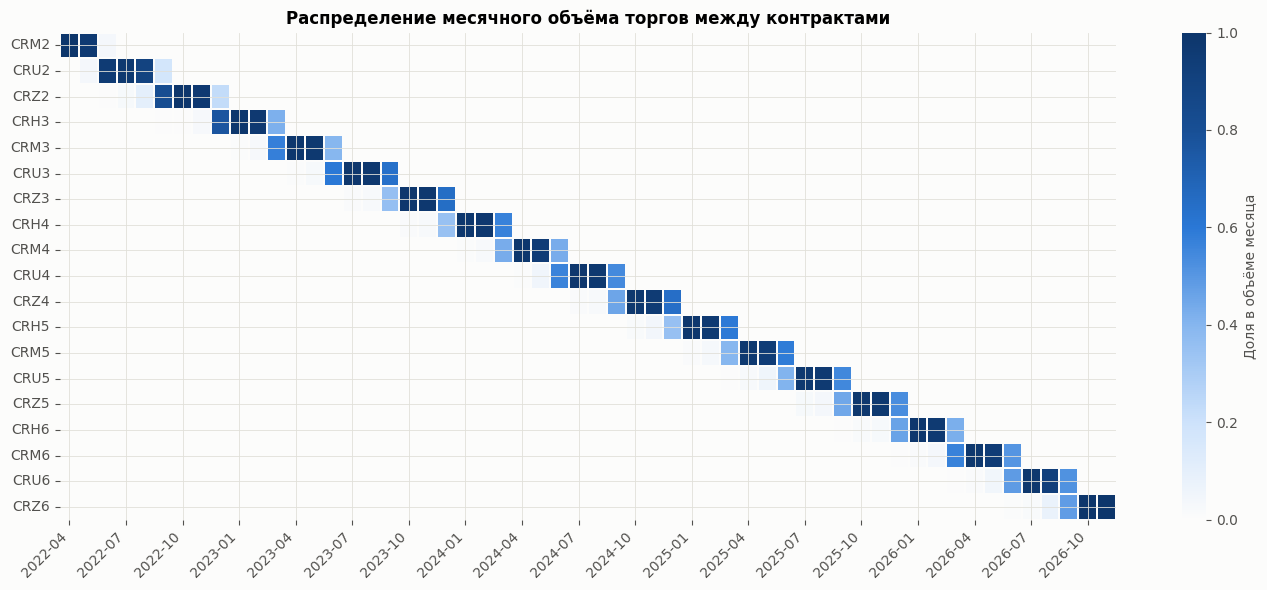

In [15]:
# Доля каждого контракта в месячном объёме всей серии
monthly = raw.groupby([raw["begin"].dt.to_period("M"), "ticker"])["volume"].sum().unstack(fill_value=0)
monthly_share = monthly.div(monthly.sum(axis=1), axis=0)[contract_order].T

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(monthly_share, cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Доля в объёме месяца"},
            linewidths=0.3, linecolor="#fcfcfb")
ax.set_xticks(np.arange(0, monthly_share.shape[1], 3) + 0.5)
ax.set_xticklabels([str(p) for p in monthly_share.columns[::3]], rotation=45, ha="right")
ax.set_title("Распределение месячного объёма торгов между контрактами")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Вывод по жизненному циклу ликвидности.**
- У всех контрактов одинаковый жизненный цикл: год и более почти нет торгов, затем за ~13 недель до исполнения объём растёт на 2–3 порядка, и последние три месяца контракт — главный инструмент серии. На последние 91 день приходится 91–99,9% объёма каждого контракта (медиана 94%).
- На тепловой карте ликвидность движется «лесенкой»: в каждом месяце основная часть объёма серии приходится на один контракт — ближайший.
- **Практический вывод для п. 2:** ценовой ряд на основе ближайшего контракта отражает основной рынок; дальние контракты имеет смысл использовать только как источник информации о временной структуре (контанго), но не как самостоятельный ряд для прогноза — их цены формируются редкими сделками.

### 2.5 Какой контракт самый ликвидный и когда «переходит» ликвидность

In [16]:
dv = daily.pivot(index="date", columns="ticker", values="volume").fillna(0)[contract_order]
nearest_by_date = pd.Series(expiry.index.to_numpy()[np.searchsorted(exp_values, dv.index.to_numpy(), side="left")],
                            index=dv.index)
leader = dv.idxmax(axis=1)
nearest_share = pd.Series([dv.at[d, t] for d, t in nearest_by_date.items()], index=dv.index) / dv.sum(axis=1)

print(f"Ближайший контракт — самый ликвидный в {(leader == nearest_by_date).mean():.1%} торговых дней")
print(f"Средняя доля ближайшего контракта в дневном объёме серии: {nearest_share.mean():.1%}")

handover = []
for old, new in zip(contract_order[:-1], contract_order[1:]):
    exp_day = expiry[old]
    if exp_day > DATA_END:
        continue
    window = dv.loc[(dv.index > exp_day - pd.Timedelta(days=60)) & (dv.index < exp_day), [old, new]]
    overtake = window.index[window[new] > window[old]]
    day_before = window.index.max()
    exp_hours = raw[(raw["date"] == exp_day) & (raw["begin"].dt.hour < 14) & raw["ticker"].isin([old, new])]
    exp_hours = exp_hours.groupby("ticker")["volume"].sum()
    handover.append({
        "old": old, "new": new, "expiry": exp_day.date(),
        "new_overtakes_before_expiry": overtake.min().date() if len(overtake) else None,
        "new_share_day_before": dv.at[day_before, new] / dv.loc[day_before, [old, new]].sum(),
        "new_share_expiry_day_before_14h": exp_hours.get(new, 0) / exp_hours.sum(),
    })
handover_df = pd.DataFrame(handover)
handover_df

Ближайший контракт — самый ликвидный в 98.0% торговых дней
Средняя доля ближайшего контракта в дневном объёме серии: 93.5%


,old,new,expiry,new_overtakes_before_expiry,new_share_day_before,new_share_expiry_day_before_14h
0,CRM2,CRU2,2022-06-16,2022-06-14,0.649753,0.751132
1,CRU2,CRZ2,2022-09-15,2022-09-07,0.545149,0.498376
2,CRZ2,CRH3,2022-12-15,None,0.46905,0.648
3,CRH3,CRM3,2023-03-16,None,0.429799,0.731464
4,CRM3,CRU3,2023-06-15,None,0.300368,0.321786
5,CRU3,CRZ3,2023-09-21,None,0.388946,0.647538
6,CRZ3,CRH4,2023-12-21,None,0.365639,0.700105
7,CRH4,CRM4,2024-03-21,None,0.376183,0.694661
8,CRM4,CRU4,2024-06-20,None,0.467998,0.728247
9,CRU4,CRZ4,2024-09-19,None,0.439224,0.619116


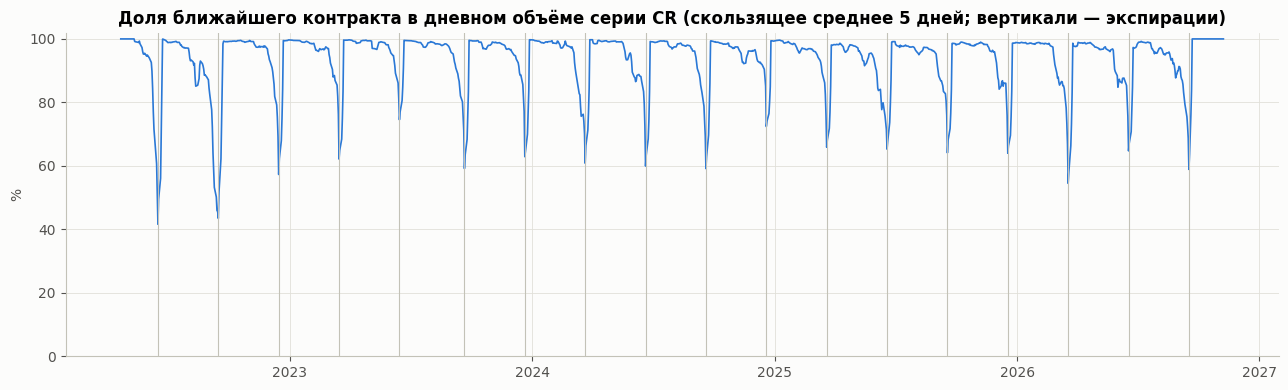

In [17]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(nearest_share.index, nearest_share.rolling(5, min_periods=1).mean() * 100, color=PALETTE[0], linewidth=1.2)
for t in contract_order[:-1]:
    if expiry[t] <= DATA_END:
        ax.axvline(expiry[t], color="#c3c2b7", linewidth=0.8)
ax.set_ylim(0, 102)
ax.set_title("Доля ближайшего контракта в дневном объёме серии CR (скользящее среднее 5 дней; вертикали — экспирации)")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()

**Вывод по переходу ликвидности.**
- Ближайший контракт — самый ликвидный в 98% торговых дней, его средняя доля в дневном объёме серии — 93,5%. Провалы доли видны только около дней экспирации.
- Начиная с `CRZ2` (декабрь 2022) **следующий контракт ни разу не обогнал текущий по дневному объёму до дня экспирации**. Но переход идёт в последние 1–2 дня: за день до экспирации на новый контракт приходится уже 25–50% объёма пары, а в день экспирации до 14:00 — 32–75% (обычно около 2/3). В 2022 г. (`CRM2`→`CRU2`, `CRU2`→`CRZ2`) ликвидность переходила на 2–8 дней раньше.
- **Рекомендация для п. 2:** текущее правило (старый контракт до 14:00 дня экспирации) в целом согласуется с ликвидностью, но в последнюю торговую сессию старый контракт уже не основной. Для сравнения стоит построить вариант с переключением **в начале дня экспирации** (или в конце предыдущего дня) и вариант «по объёму» — это и есть несколько вариантов единого ряда из задания.

### 2.6 Цены контрактов и временная структура (контанго)

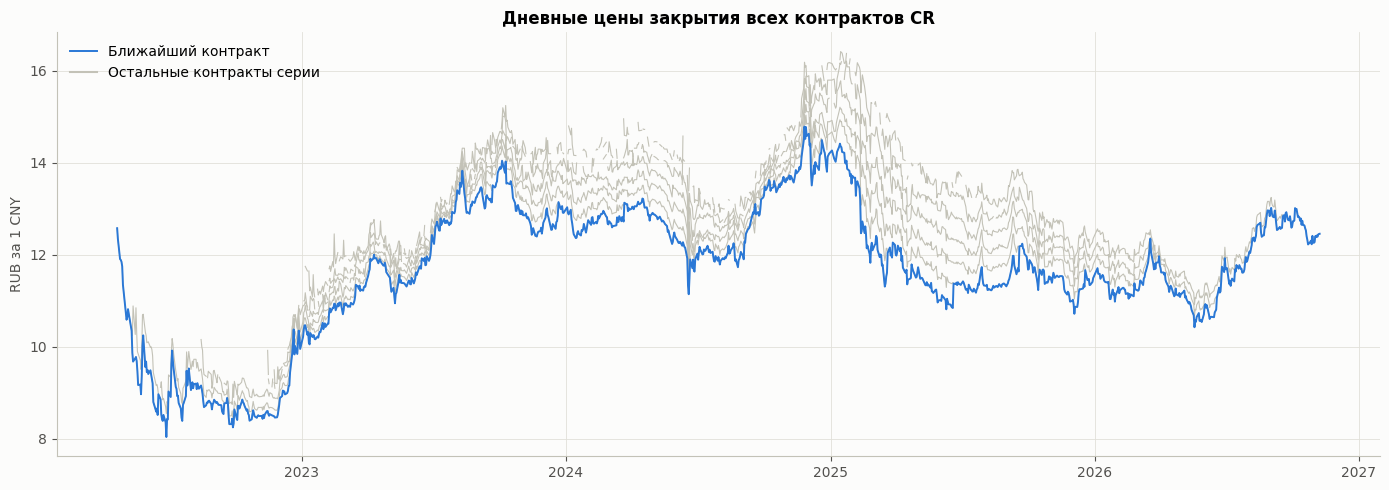

In [18]:
daily_close = daily.pivot(index="date", columns="ticker", values="close")[contract_order]
near_close = pd.Series([daily_close.at[d, t] for d, t in nearest_by_date.items()], index=daily_close.index)

fig, ax = plt.subplots(figsize=(14, 5))
for t in contract_order:
    ax.plot(daily_close.index, daily_close[t], color="#c3c2b7", linewidth=0.8)
ax.plot(near_close.index, near_close.values, color=PALETTE[0], linewidth=1.4, label="Ближайший контракт")
ax.plot([], [], color="#c3c2b7", label="Остальные контракты серии")
ax.set_title("Дневные цены закрытия всех контрактов CR")
ax.set_ylabel("RUB за 1 CNY")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

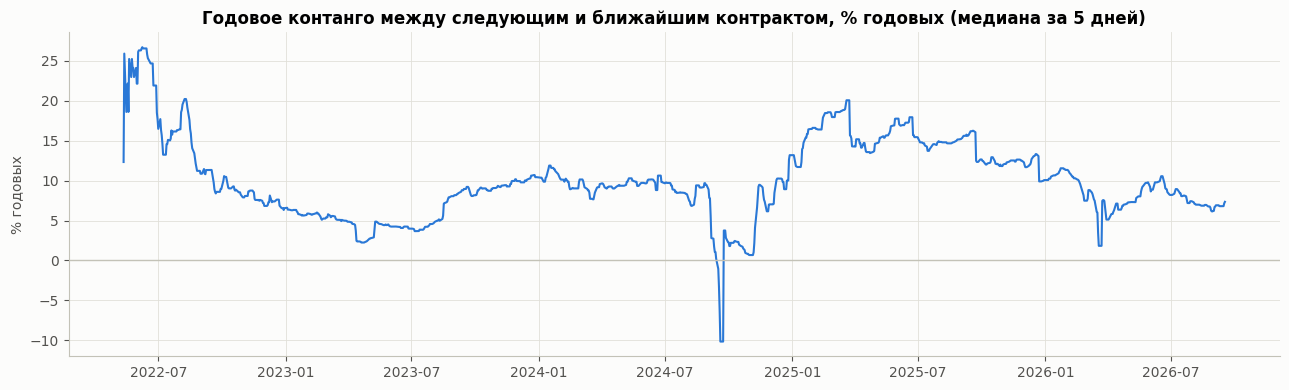

,spread_pct,carry_annual_pct
begin,,
2022,2.73973,10.8412
2023,1.42684,5.68261
2024,2.29894,9.11662
2025,3.74666,14.7531
2026,1.96636,7.8105


In [19]:
# Годовое контанго между следующим и ближайшим контрактом по синхронным 10-минутным ценам
close_wide = raw.pivot(index="begin", columns="ticker", values="close")
col_idx = {t: i for i, t in enumerate(close_wide.columns)}
arr = close_wide.to_numpy()
ts_dates = close_wide.index.normalize().to_numpy()
p = np.searchsorted(exp_values, ts_dates, side="left")
has_next = p + 1 < len(expiry)
near_t = expiry.index.to_numpy()[p]
next_t = expiry.index.to_numpy()[np.minimum(p + 1, len(expiry) - 1)]
rows = np.arange(len(arr))
near_px = arr[rows, [col_idx[t] for t in near_t]]
next_px = np.where(has_next, arr[rows, [col_idx[t] for t in next_t]], np.nan)

basis = pd.DataFrame({"near": near_px, "next": next_px,
                      "dt_years": (expiry.to_numpy()[np.minimum(p + 1, len(expiry) - 1)] - expiry.to_numpy()[p])
                      / np.timedelta64(365, "D")}, index=close_wide.index).dropna()
basis["spread_pct"] = (basis["next"] / basis["near"] - 1) * 100
basis["carry_annual_pct"] = np.log(basis["next"] / basis["near"]) / basis["dt_years"] * 100
basis_daily = basis.groupby(basis.index.normalize()).last()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(basis_daily.index, basis_daily["carry_annual_pct"].rolling(5, min_periods=1).median(), color=PALETTE[0])
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Годовое контанго между следующим и ближайшим контрактом, % годовых (медиана за 5 дней)")
ax.set_ylabel("% годовых")
plt.tight_layout()
plt.show()

basis_daily.groupby(basis_daily.index.year)[["spread_pct", "carry_annual_pct"]].median()

**Вывод по ценам и временной структуре.**
- Все контракты движутся синхронно (один базовый актив), но **дальние контракты почти всегда дороже ближних** — устойчивое контанго. Медианный спред между следующим и ближайшим контрактом по годам — 1,4–3,7% за квартал, т. е. ≈ 6–15% годовых (минимум в 2023 г., максимум в 2025 г.).
- Экономический смысл: по паритету процентных ставок форвардная цена юаня в рублях растёт со ставкой, равной разнице рублёвой и юаневой процентных ставок. Поэтому контанго — это **процентная составляющая, а не прогноз курса**, и при переходе со старого контракта на новый цена механически «подпрыгивает» на величину спреда — это roll gap, который обязательно нужно убирать (раздел 3).
- Периоды аномального спреда (2022 г., отдельные эпизоды 2024 г.) совпадают с периодами высокой волатильности и низкой ликвидности дальних контрактов.

### 2.7 Доходности внутри каждого контракта (без склейки)

In [20]:
raw["ret_10m_prev"] = raw.groupby("ticker")["ret_10m"].shift(1)


def return_stats(d):
    r = d["ret_10m"].dropna()
    pair = d[["ret_10m", "ret_10m_prev"]].dropna()
    dclose = d.groupby("date")["close"].last()
    return pd.Series({
        "n_returns": len(r),
        "std_10m_pct": r.std() * 100,
        "annual_vol_daily_pct": np.log(dclose).diff().std() * np.sqrt(252) * 100,
        "skew": r.skew(),
        "excess_kurtosis": r.kurt(),
        "acf1": pair["ret_10m"].corr(pair["ret_10m_prev"]),
        "acf1_squared": (pair["ret_10m"] ** 2).corr(pair["ret_10m_prev"] ** 2),
        "share_abs_gt_0.5pct": (r.abs() > 0.005).mean() * 100,
    })


cols = raw.columns.drop("ticker")
ret_stats_nearest = raw[raw["is_nearest"]].groupby("ticker")[cols].apply(return_stats).loc[contract_order]
ret_stats_far = raw[~raw["is_nearest"]].groupby("ticker")[cols].apply(return_stats)
ret_stats_nearest["acf1_when_far"] = ret_stats_far["acf1"]
ret_stats_nearest

,n_returns,std_10m_pct,annual_vol_daily_pct,skew,excess_kurtosis,acf1,acf1_squared,share_abs_gt_0.5pct,acf1_when_far
ticker,,,,,,,,,
CRM2,"1,456",0.609353,44.4171,0.0260715,4.87236,-0.249048,0.267452,29.3269,NaN
CRU2,"4,627",0.242373,37.3777,0.386785,10.2023,-0.156654,0.244123,4.64664,-0.257112
CRZ2,"5,442",0.134492,18.792,-0.257534,26.1183,-0.0879529,0.204155,0.91878,-0.1485
CRH3,"5,266",0.126212,24.494,-0.203642,22.2744,-0.00377434,0.170108,0.873528,-0.117715
CRM3,"5,267",0.0883154,14.4402,-1.12466,25.054,-0.0218893,0.235274,0.24682,-0.102968
CRU3,"5,979",0.107876,16.7151,-1.16194,31.1287,-0.0129726,0.158409,0.38468,-0.122404
CRZ3,"5,572",0.0849488,14.4776,-2.06916,35.2697,0.000256491,0.111127,0.107681,-0.106604
CRH4,"5,250",0.066876,11.3774,-0.121181,5.03591,-0.0147879,0.113198,0.0190476,-0.206992
CRM4,"5,388",0.0927323,15.0084,-9.71217,464.44,-0.0498279,0.242301,0.278396,-0.142796


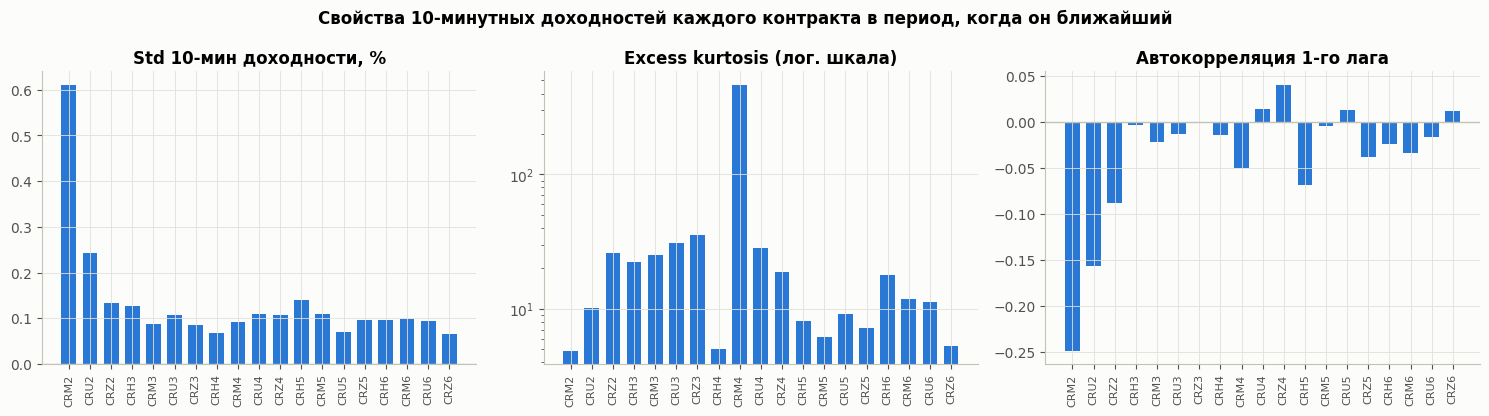

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(contract_order))
panels = [("std_10m_pct", "Std 10-мин доходности, %"),
          ("excess_kurtosis", "Excess kurtosis (лог. шкала)"),
          ("acf1", "Автокорреляция 1-го лага")]
for ax, (col, title) in zip(axes, panels):
    ax.bar(x, ret_stats_nearest[col], color=PALETTE[0], width=0.7)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(contract_order, rotation=90, fontsize=8)
    ax.axhline(0, color="#c3c2b7", linewidth=1)
axes[1].set_yscale("log")
fig.suptitle("Свойства 10-минутных доходностей каждого контракта в период, когда он ближайший", fontweight="bold")
plt.tight_layout()
plt.show()

**Вывод по доходностям внутри контрактов.**
- **Автокорреляция первого лага зависит от ликвидности.** В дальних, неликвидных контрактах она стабильно отрицательная (`acf1_when_far` от −0,07 до −0,37) — это «отскок между bid и ask» (bid-ask bounce) при редких сделках. У ближайшего контракта она заметна только в 2022 г. (`CRM2` −0,25, `CRU2` −0,16, `CRZ2` −0,09), а начиная с `CRH3` колеблется около нуля (от −0,07 до +0,04). Значит, ACF(1) ≈ −0,1 склеенного ряда (раздел 4) в основном создаётся 2022 годом — см. проверку в 4.3.
- Тяжёлые хвосты (excess kurtosis от 5 до сотен; рекорд — `CRM4`, 464, из-за июня 2024 г.) и кластеризация волатильности (`acf1_squared` 0,07–0,27) есть во всех контрактах.
- Волатильность 2022 г. (`CRM2`, `CRU2`) в 2–4 раза выше последующих периодов (годовая 37–44% против 11–24%) — **отдельный режим рынка**. Начиная с `CRM3` std 10-минутной доходности стабильно ≈ 0,07–0,14%.
- Рекомендация: обучать модели на двух вариантах выборки — полной и начиная с осени 2022 г. — и сравнивать качество.

### 2.8 Внутридневная и недельная сезонность (ближайший контракт)

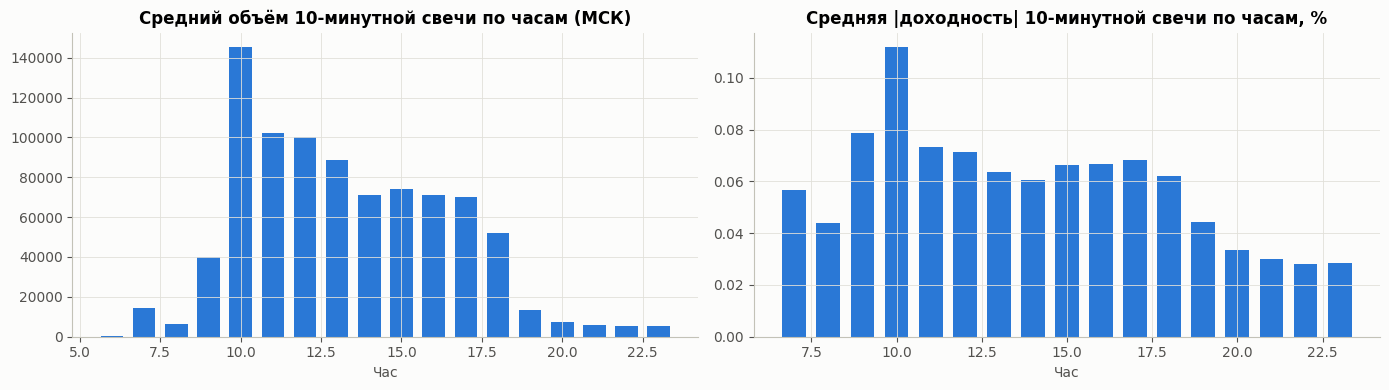

,candles,mean_volume,mean_abs_ret_pct
dow,,,
0,17354,"55,823.6",0.0615361
1,17458,"55,646.1",0.0570367
2,17325,"60,179.7",0.0603302
3,16480,"61,093.7",0.0609196
4,17293,"59,449.4",0.0616679
5,1056,"10,684.1",0.0285768
6,710,"2,056.55",0.0168262


In [22]:
near_recent = raw[raw["is_nearest"] & (raw["begin"] >= "2023-01-01")].copy()
near_recent["hour"] = near_recent["begin"].dt.hour
by_hour = near_recent.groupby("hour").agg(candles=("begin", "size"), mean_volume=("volume", "mean"),
                                          mean_abs_ret_pct=("ret_10m", lambda x: x.abs().mean() * 100))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_hour.index, by_hour["mean_volume"], color=PALETTE[0], width=0.7)
axes[0].set_title("Средний объём 10-минутной свечи по часам (МСК)")
axes[0].set_xlabel("Час")
axes[1].bar(by_hour.index, by_hour["mean_abs_ret_pct"], color=PALETTE[0], width=0.7)
axes[1].set_title("Средняя |доходность| 10-минутной свечи по часам, %")
axes[1].set_xlabel("Час")
plt.tight_layout()
plt.show()

near_recent["dow"] = near_recent["begin"].dt.dayofweek
near_recent.groupby("dow").agg(candles=("begin", "size"), mean_volume=("volume", "mean"),
                               mean_abs_ret_pct=("ret_10m", lambda x: x.abs().mean() * 100))

**Вывод по сезонности.**
- Ярко выражена внутридневная сезонность: пик объёма и волатильности — в первый час основной сессии (10:00), далее плавное снижение; в вечерней сессии (19:00–23:50) объём в 10–20 раз ниже, а средний модуль доходности в 2–3 раза ниже, чем в основной сессии. Утренняя сессия (08:50/09:00, с 2026 г. — с 06:50) тоже малоактивна.
- Будни между собой почти не различаются; в субботу средний объём свечи в ~5 раз ниже будничного, в воскресенье — почти в 30 раз ниже.
- Следствие: **час суток и тип сессии — обязательные признаки**, а метрики модели стоит дополнительно смотреть отдельно для основной и вечерней сессий: шум и масштаб доходностей там разные.

### 2.9 Итог по EDA контрактов

| Вопрос | Ответ |
|---|---|
| Качество данных | Пропусков, дублей и ошибок OHLC нет ни в одном контракте; `value` ≡ 0 — удаляем |
| Почему сетка нерегулярна | Свечи есть только при сделках; разрывы концентрируются в дальних контрактах. Пока контракт ближайший — 98,8–100% шагов ровно 10 мин |
| Где ликвидность | 93,5% дневного объёма серии — в ближайшем контракте; ≈ 92–94% объёма контракта — в последний квартал жизни |
| Когда переключаться | Ликвидность переходит в последние 1–2 дня перед экспирацией (с конца 2022 г.), в 2022 г. — на 2–8 дней раньше |
| Чем отличаются цены | Устойчивое контанго 1,4–3,7% за квартал (6–15% годовых) → roll gaps при склейке; цены дальних контрактов шумные |
| Одинаковы ли свойства доходностей | Тяжёлые хвосты и кластеры волатильности — во всех контрактах. Отрицательный AR(1) — только в дальних контрактах и в 2022 г.; 2022 г. — отдельный высоковолатильный режим |
| Сезонность | Сильная внутридневная: пик в 10:00, тихая вечерняя сессия, сессии выходного дня |

## 3. Единый временной ряд: front-contract и roll-корректировка (задание 2)

**Вариант 1 — front-contract (без корректировки).** Каждый контракт используется до окончания торгов в день его экспирации, затем ряд переключается на следующий. Это ровно свечи с `is_nearest == True`.

In [23]:
front_series = (raw.loc[raw["is_nearest"], raw_all_10m.columns]
                .sort_values("begin").reset_index(drop=True))

front_switches = front_series[front_series["ticker"] != front_series["ticker"].shift(1)][["begin", "ticker", "close", "volume"]]
print("Наблюдений в front-ряду:", len(front_series), "| контрактов:", front_series["ticker"].nunique())
print("Дубликатов времени:", front_series["begin"].duplicated().sum())
front_switches

Наблюдений в front-ряду: 100637 | контрактов: 19
Дубликатов времени: 0


,begin,ticker,close,volume
0,2022-04-21 10:00:00,CRM2,12.99,2
1656,2022-06-17 10:10:00,CRU2,9.13,81
6423,2022-09-16 09:00:00,CRZ2,8.79,6003
11993,2022-12-16 09:00:00,CRH3,9.39,34920
17385,2023-03-17 09:00:00,CRM3,11.248,52215
22777,2023-06-16 09:00:00,CRU3,11.866,88109
28896,2023-09-22 09:00:00,CRZ3,13.434,77298
34597,2023-12-22 08:50:00,CRH4,13.119,325
39968,2024-03-22 08:50:00,CRM4,13.061,404
45481,2024-06-21 09:50:00,CRU4,12.224,993


In [24]:
# Сколько свечей нового контракта в день экспирации старого не попадает в ряд (вечерняя сессия дня экспирации)
lost = []
for old, new in zip(contract_order[:-1], contract_order[1:]):
    if expiry[old] > DATA_END:
        continue
    lost_rows = raw[(raw["ticker"] == new) & (raw["date"] == expiry[old]) & (raw["begin"].dt.hour >= 14)]
    lost.append({"roll": f"{old}->{new}", "candles_after_14h": len(lost_rows)})
lost = pd.DataFrame(lost)
print("Свечей нового контракта после 14:00 в дни экспирации, не вошедших в ряд:", lost["candles_after_14h"].sum())

Свечей нового контракта после 14:00 в дни экспирации, не вошедших в ряд: 1013


**Замечание.** Front-ряд корректен хронологически: 19 контрактов, без дублей, старые контракты не возвращаются. Но после окончания торгов старого контракта в 14:00 дня экспирации ряд «молчит» до утра следующего дня, хотя новый контракт в это время торгуется (дневная + вечерняя сессия: 1013 свечей на 18 переходов, ≈ 56 на каждый). Улучшение для п. 2: переключаться на новый контракт **в 14:00 дня экспирации**, а не на следующий день.

**Roll gaps.** Цена в момент переключения сравнивается в один и тот же момент времени (последняя общая 10-минутная свеча старого и нового контракта в день экспирации).

In [25]:
roll_rows = []
for old, new in zip(contract_order[:-1], contract_order[1:]):
    roll_date = expiry[old]
    if roll_date > DATA_END:
        continue
    pair = raw[raw["ticker"].isin([old, new]) & (raw["date"] == roll_date)].pivot(index="begin", columns="ticker", values="close")
    common = pair.dropna()
    last_common = common.index.max()
    roll_rows.append({"old_ticker": old, "new_ticker": new, "roll_date": roll_date, "common_time": last_common,
                      "old_close": common.at[last_common, old], "new_close": common.at[last_common, new]})
sync_roll_gaps_df = pd.DataFrame(roll_rows)
sync_roll_gaps_df["roll_gap"] = sync_roll_gaps_df["new_close"] - sync_roll_gaps_df["old_close"]
sync_roll_gaps_df["roll_gap_pct"] = (sync_roll_gaps_df["new_close"] / sync_roll_gaps_df["old_close"] - 1) * 100
display(sync_roll_gaps_df)
display(sync_roll_gaps_df[["roll_gap", "roll_gap_pct"]].describe().T)
print("Положительных:", (sync_roll_gaps_df["roll_gap"] > 0).sum(), "| отрицательных:", (sync_roll_gaps_df["roll_gap"] < 0).sum())

,old_ticker,new_ticker,roll_date,common_time,old_close,new_close,roll_gap,roll_gap_pct
0,CRM2,CRU2,2022-06-16,2022-06-16 13:50:00,8.52,9.06,0.54,6.33803
1,CRU2,CRZ2,2022-09-15,2022-09-15 13:50:00,8.54,8.75,0.21,2.45902
2,CRZ2,CRH3,2022-12-15,2022-12-15 13:50:00,9.159,9.379,0.22,2.40201
3,CRH3,CRM3,2023-03-16,2023-03-16 13:50:00,11.111,11.161,0.05,0.450005
4,CRM3,CRU3,2023-06-15,2023-06-15 13:50:00,11.699,11.814,0.115,0.98299
5,CRU3,CRZ3,2023-09-21,2023-09-21 13:50:00,13.145,13.416,0.271,2.06162
6,CRZ3,CRH4,2023-12-21,2023-12-21 13:50:00,12.853,13.2,0.347,2.69976
7,CRH4,CRM4,2024-03-21,2024-03-21 13:50:00,12.725,13.023,0.298,2.34185
8,CRM4,CRU4,2024-06-20,2024-06-20 13:50:00,11.485,11.86,0.375,3.26513
9,CRU4,CRZ4,2024-09-19,2024-09-19 13:50:00,13.106,12.711,-0.395,-3.01389


,count,mean,std,min,25%,50%,75%,max
roll_gap,18,0.276889,0.244167,-0.395,0.2125,0.3095,0.4195,0.595
roll_gap_pct,18,2.50825,2.17236,-3.01389,2.13168,2.50463,3.46951,6.33803


Положительных: 16 | отрицательных: 2


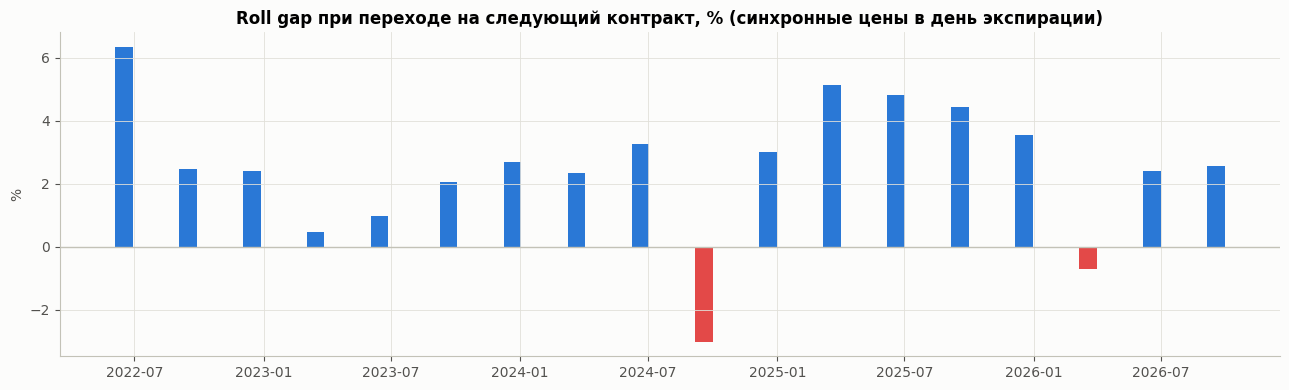

In [26]:
fig, ax = plt.subplots(figsize=(13, 4))
colors = [PALETTE[0] if v >= 0 else PALETTE[7] for v in sync_roll_gaps_df["roll_gap_pct"]]
ax.bar(sync_roll_gaps_df["roll_date"], sync_roll_gaps_df["roll_gap_pct"], width=25, color=colors)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Roll gap при переходе на следующий контракт, % (синхронные цены в день экспирации)")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()

**Вывод по roll gaps.** В 16 из 18 переходов новый контракт дороже старого; средний разрыв ≈ 2,5%, максимум ≈ 6,3%, минимум ≈ −3,0%. Это величина квартального контанго из раздела 2.6. При механической склейке такие скачки попали бы в доходность как «рыночные» движения размером в среднем ≈ 18 стандартных отклонений 10-минутной доходности (средняя |доходность| в точках перехода без корректировки — 3,2%, после — 0,6%), поэтому их необходимо устранить.

**Вариант 2 — аддитивная roll-корректировка (back-adjusted ряд, `rolled_*`).** Из цен каждого следующего контракта вычитается накопленная сумма roll gaps.

In [27]:
roll_adjustments = sync_roll_gaps_df[["new_ticker", "roll_gap"]].copy()
roll_adjustments["cumulative_roll_gap"] = roll_adjustments["roll_gap"].cumsum()

rolled_series = front_series.copy()
rolled_series["roll_adjustment"] = rolled_series["ticker"].map(
    roll_adjustments.set_index("new_ticker")["cumulative_roll_gap"]).fillna(0.0)
for column in ["open", "high", "low", "close"]:
    rolled_series[f"rolled_{column}"] = rolled_series[column] - rolled_series["roll_adjustment"]

# Проверка 1: в точках перехода остаточный разрыв равен нулю
adj = rolled_series.groupby("ticker")["roll_adjustment"].first()
residual = ((sync_roll_gaps_df["new_close"] - sync_roll_gaps_df["new_ticker"].map(adj))
            - (sync_roll_gaps_df["old_close"] - sync_roll_gaps_df["old_ticker"].map(adj)))
print("Максимальный остаточный разрыв:", residual.abs().max())

# Проверка 2: OHLC-логика сохраняется
bad = ((rolled_series["rolled_high"] < rolled_series[["rolled_open", "rolled_close"]].max(axis=1)) |
       (rolled_series["rolled_low"] > rolled_series[["rolled_open", "rolled_close"]].min(axis=1)))
print("OHLC-ошибок после корректировки:", bad.sum())
print("rolled_close: min =", rolled_series["rolled_close"].min(), "| max =", rolled_series["rolled_close"].max())
print("Накопленная корректировка к концу ряда:", roll_adjustments["cumulative_roll_gap"].iloc[-1])

Максимальный остаточный разрыв: 0.0
OHLC-ошибок после корректировки: 0
rolled_close: min = 5.985000000000001 | max = 13.131
Накопленная корректировка к концу ряда: 4.984


**Вариант 3 — индекс по методике López de Prado (`rprice`).** У аддитивно скорректированного ряда уровень «уезжает» вниз (накопленная корректировка ≈ 5 руб. при цене ≈ 12 руб.), поэтому процентное изменение `rolled_close` искажено: делить на 6–7 руб. вместо реальных 11–12 некорректно. Доходность считается как приращение скорректированной цены, делённое на **реальную** цену контракта на предыдущем шаге:

$$r_t = \frac{\text{rolled\_close}_t - \text{rolled\_close}_{t-1}}{\text{close}_{t-1}},\qquad \text{rprice}_t = \prod_{s\le t}(1+r_s)$$

`rprice` — неотрицательный индекс «стоимости позиции, переносимой из контракта в контракт».

In [28]:
rolled_series["return_ldp"] = rolled_series["rolled_close"].diff() / rolled_series["close"].shift(1)
rolled_series["log_return_ldp"] = np.log1p(rolled_series["return_ldp"])
rolled_series["rprice"] = (1 + rolled_series["return_ldp"].fillna(0)).cumprod()
rolled_series["log_return_naive"] = np.log(rolled_series["close"]).diff()   # без корректировки — для сравнения

switch_mask = rolled_series["ticker"] != rolled_series["ticker"].shift(1)
cmp = rolled_series.loc[switch_mask, ["begin", "ticker", "log_return_naive", "log_return_ldp"]].iloc[1:]
print("Средняя |доходность| в точках перехода: без корректировки "
      f"{cmp['log_return_naive'].abs().mean():.4f}, после корректировки {cmp['log_return_ldp'].abs().mean():.4f}")
cmp

Средняя |доходность| в точках перехода: без корректировки 0.0323, после корректировки 0.0059


,begin,ticker,log_return_naive,log_return_ldp
1656,2022-06-17 10:10:00,CRU2,0.0691494,0.0081824
6423,2022-09-16 09:00:00,CRZ2,0.0288537,0.00467291
11993,2022-12-16 09:00:00,CRH3,0.0249083,0.00120028
17385,2023-03-17 09:00:00,CRM3,0.0122547,0.00779958
22777,2023-06-16 09:00:00,CRU3,0.0141738,0.00443498
28896,2023-09-22 09:00:00,CRZ3,0.0217473,0.00136841
34597,2023-12-22 08:50:00,CRH4,0.0204843,-0.00632197
39968,2024-03-22 08:50:00,CRM4,0.0260621,0.0029818
45481,2024-06-21 09:50:00,CRU4,0.0623594,0.0312016
50789,2024-09-20 09:50:00,CRZ4,-0.0322559,-0.0016036


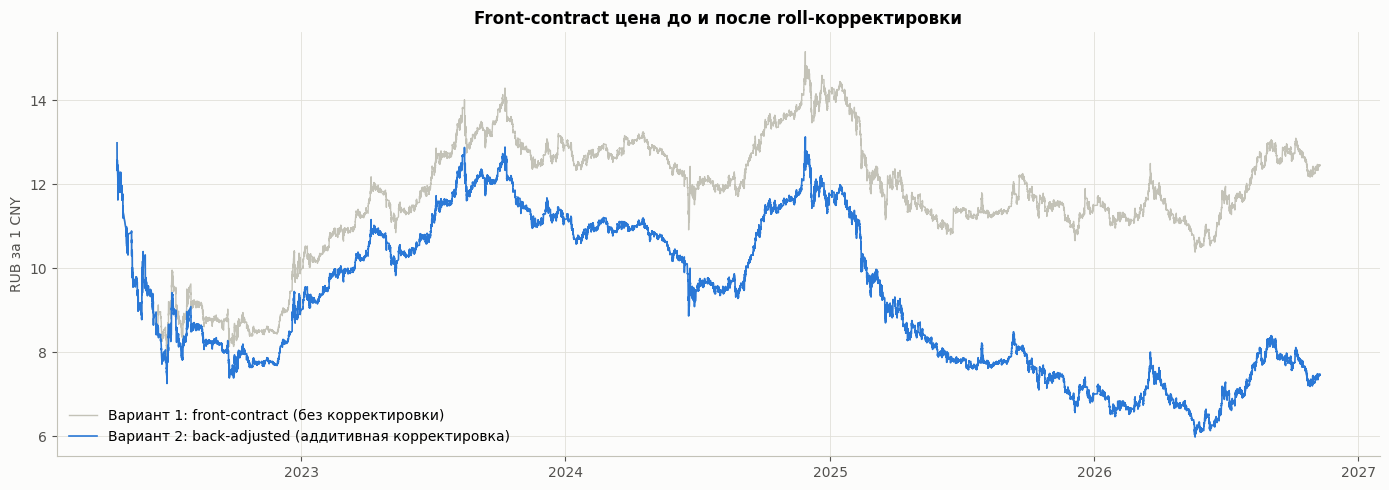

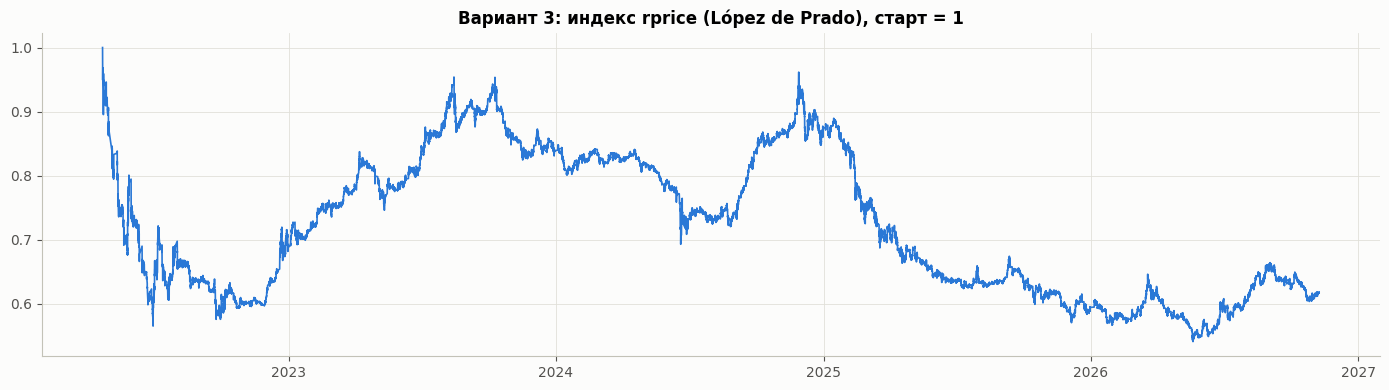

In [29]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(rolled_series["begin"], rolled_series["close"], color="#c3c2b7", linewidth=1, label="Вариант 1: front-contract (без корректировки)")
ax.plot(rolled_series["begin"], rolled_series["rolled_close"], color=PALETTE[0], linewidth=1.2, label="Вариант 2: back-adjusted (аддитивная корректировка)")
ax.set_title("Front-contract цена до и после roll-корректировки")
ax.set_ylabel("RUB за 1 CNY")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(rolled_series["begin"], rolled_series["rprice"], color=PALETTE[0], linewidth=1.2)
ax.set_title("Вариант 3: индекс rprice (López de Prado), старт = 1")
plt.tight_layout()
plt.show()

**Вывод по единому ряду.**

| Вариант | Для чего пригоден | Ограничение |
|---|---|---|
| 1. Front-contract `close` | Реальный уровень цены, торговые сигналы, исполнение | Содержит 18 искусственных скачков (roll gaps) |
| 2. Back-adjusted `rolled_close` | Технические индикаторы на уровне цены (MA, RSI, каналы) | Уровень не равен реальной цене, % изменения искажены |
| 3. `rprice` / `return_ldp` | Доходности, статистика, обучение моделей | Уровень — индекс, а не цена |

Остаточный разрыв в точках перехода равен нулю, OHLC-логика сохранена, `rolled_close` положителен на всей выборке. Для дальнейшего анализа используется `log_return_ldp = ln(1 + return_ldp)`. Доходность в точке перехода не обязана быть нулевой: между 13:50 дня экспирации и первой свечой нового контракта на следующий день рынок реально двигается.

## 4. Логарифмические доходности непрерывного ряда (задание 3)

In [30]:
returns = rolled_series["log_return_ldp"].dropna()
print("Наблюдений доходности:", len(returns))
display(rolled_series[["return_ldp", "log_return_ldp", "rprice"]].describe().T)
print("Минимальная простая доходность:", rolled_series["return_ldp"].min(), "| есть ли r <= -100%:", (rolled_series["return_ldp"] <= -1).any())

Наблюдений доходности: 100636


,count,mean,std,min,25%,50%,75%,max
return_ldp,"100,636",-3.81621e-06,0.00139512,-0.0414097,-0.000382744,0,0.00038125,0.04158
log_return_ldp,"100,636",-4.78968e-06,0.00139545,-0.0422915,-0.000382817,0,0.000381177,0.0407388
rprice,"100,637",0.718007,0.108291,0.540718,0.622598,0.703391,0.821811,1


Минимальная простая доходность: -0.04140969162995585 | есть ли r <= -100%: False


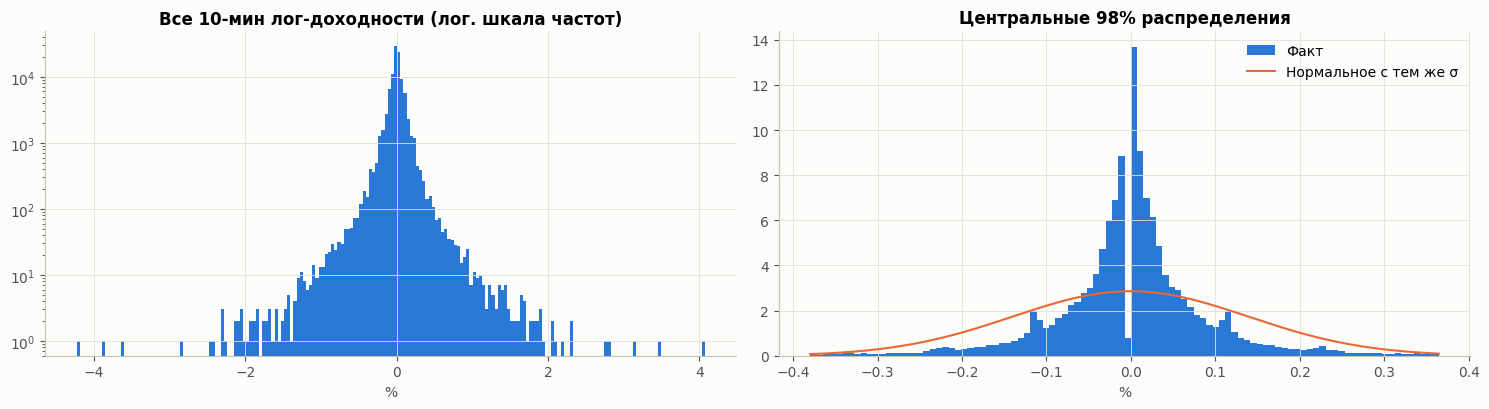

Skewness: -0.398 | Excess kurtosis: 75.31
Доля нулевых доходностей: 0.0955
Jarque–Bera p-value: 0.0


0.001    -0.0109625
0.005   -0.00547947
0.01    -0.00379687
0.05    -0.00162962
0.5               0
0.95     0.00159965
0.99     0.00364708
0.995    0.00525398
0.999     0.0105512
Name: log_return_ldp, dtype: float64

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].hist(returns * 100, bins=200, color=PALETTE[0])
axes[0].set_yscale("log")
axes[0].set_title("Все 10-мин лог-доходности (лог. шкала частот)")
axes[0].set_xlabel("%")
central = returns[(returns >= returns.quantile(0.01)) & (returns <= returns.quantile(0.99))]
axes[1].hist(central * 100, bins=100, color=PALETTE[0], density=True, label="Факт")
grid = np.linspace(central.min(), central.max(), 300)
axes[1].plot(grid * 100, stats.norm.pdf(grid, returns.mean(), returns.std()) / 100, color=PALETTE[1],
             label="Нормальное с тем же σ")
axes[1].set_title("Центральные 98% распределения")
axes[1].set_xlabel("%")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Skewness:", round(returns.skew(), 3), "| Excess kurtosis:", round(returns.kurt(), 2))
print("Доля нулевых доходностей:", round((returns == 0).mean(), 4))
print("Jarque–Bera p-value:", stats.jarque_bera(returns).pvalue)
returns.quantile([0.001, 0.005, 0.01, 0.05, 0.5, 0.95, 0.99, 0.995, 0.999])

In [32]:
# Устойчивость характеристик: вся выборка vs без весенне-летнего режима 2022 г. (до 16.09.2022)
r_post = rolled_series.loc[rolled_series["begin"] >= "2022-09-16", "log_return_ldp"].dropna()
pd.DataFrame({
    "вся выборка": [len(returns), returns.std() * 100, returns.skew(), returns.kurt()],
    "с 16.09.2022": [len(r_post), r_post.std() * 100, r_post.skew(), r_post.kurt()],
}, index=["n", "std, %", "skew", "excess kurtosis"])

,вся выборка,с 16.09.2022
n,"100,636","94,214"
"std, %",0.139545,0.103565
skew,-0.397552,-0.413765
excess kurtosis,75.3129,46.3839


**Вывод по распределению.** Распределение 10-минутных лог-доходностей сильно концентрируется около нуля (9,6% наблюдений — ровно 0 из-за дискретного шага цены) и имеет очень тяжёлые хвосты: excess kurtosis ≈ 75, асимметрия ≈ −0,4, тест Jarque–Bera уверенно отвергает нормальность.
98% наблюдений лежат в диапазоне ≈ ±0,37%, крайние значения — ≈ −4,2% и +4,1%. 
Без режима весны–лета 2022 г. std снижается с 0,14% до 0,10%, но excess kurtosis остаётся ≈ 46 — тяжёлые хвосты являются свойством рынка, а не нескольких аномальных дней. Предположение о нормальности некорректно → для оценки моделей лучше MAE/квантильные метрики, для моделей — робастные функции потерь (Huber).

### 4.1 Экстремальные наблюдения

In [33]:
lower_3sigma = returns.mean() - 3 * returns.std()
upper_3sigma = returns.mean() + 3 * returns.std()
outliers_3sigma = rolled_series[(rolled_series["log_return_ldp"] < lower_3sigma) | (rolled_series["log_return_ldp"] > upper_3sigma)]
print(f"Глобальное правило ±3σ: границы [{lower_3sigma:.5f}; {upper_3sigma:.5f}], "
      f"выбросов {len(outliers_3sigma)} ({len(outliers_3sigma) / len(returns):.2%}); "
      f"при нормальном распределении ожидалось бы 0,27%")

# Локальный z-score относительно предыдущих 20 дней (closed='left' — без заглядывания в будущее)
returns_local = rolled_series[["begin", "ticker", "log_return_ldp", "volume"]].dropna().set_index("begin")
roll20 = returns_local["log_return_ldp"].rolling("20D", min_periods=100, closed="left")
returns_local["rolling_mean_20d"] = roll20.mean()
returns_local["rolling_std_20d"] = roll20.std()
returns_local["rolling_zscore"] = (returns_local["log_return_ldp"] - returns_local["rolling_mean_20d"]) / returns_local["rolling_std_20d"]
returns_local["is_outlier"] = returns_local["rolling_zscore"].abs() > 3
print(f"Локальное правило |z| > 3: выбросов {returns_local['is_outlier'].sum()} "
      f"({returns_local['is_outlier'].sum() / returns_local['rolling_zscore'].notna().sum():.2%})")

display(returns_local.loc[returns_local["is_outlier"]].sort_values("rolling_zscore", key=np.abs, ascending=False).head(10))
returns_local.groupby("is_outlier")["volume"].agg(["count", "mean", "median"])

Глобальное правило ±3σ: границы [-0.00419; 0.00418], выбросов 1666 (1.66%); при нормальном распределении ожидалось бы 0,27%
Локальное правило |z| > 3: выбросов 1835 (1.83%)


,ticker,log_return_ldp,volume,rolling_mean_20d,rolling_std_20d,rolling_zscore,is_outlier
begin,,,,,,,
2024-06-19 10:00:00,CRM4,-0.0361583,912849,-8.42847e-05,0.00104658,-34.4686,True
2023-08-14 17:10:00,CRU3,-0.0185137,936795,7.49273e-05,0.00101913,-18.2398,True
2023-10-11 22:10:00,CRZ3,-0.0167368,205401,3.36041e-05,0.000922254,-18.1841,True
2024-06-21 09:50:00,CRU4,0.0312016,993,-7.26425e-05,0.00183226,17.0687,True
2023-04-07 13:30:00,CRM3,-0.0145515,265472,5.1825e-05,0.000877133,-16.6489,True
2022-12-06 09:00:00,CRZ2,0.0103605,92099,3.00917e-05,0.00067067,15.4031,True
2022-12-19 16:10:00,CRH3,-0.0145958,254080,0.000113832,0.000978679,-15.0301,True
2026-03-19 12:10:00,CRH6,-0.0141823,151982,8.11557e-05,0.000973381,-14.6536,True
2023-09-12 08:50:00,CRU3,-0.00981195,9120,8.02537e-07,0.000736375,-13.3258,True


,count,mean,median
is_outlier,,,
False,98801,"47,806.5","19,469"
True,1835,"229,479","166,851"


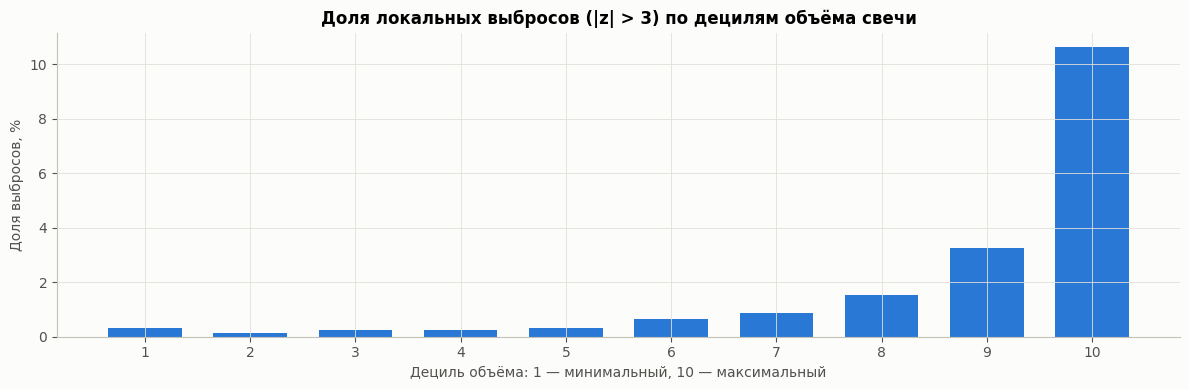

volume_decile
(0.999, 890.0]          0.337637
(890.0, 2553.0]         0.139151
(2553.0, 5687.0]        0.238569
(5687.0, 11418.0]       0.238474
(11418.0, 20245.5]      0.337871
(20245.5, 32460.0]       0.63593
(32460.0, 50116.0]      0.884428
(50116.0, 78051.0]       1.52027
(78051.0, 136109.5]       3.2694
(136109.5, 3384103.0]     10.632
Name: is_outlier, dtype: float64

In [34]:
returns_local["volume_decile"] = pd.qcut(returns_local["volume"], q=10, duplicates="drop")
outlier_rate_by_volume = returns_local.groupby("volume_decile", observed=True)["is_outlier"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(1, len(outlier_rate_by_volume) + 1), outlier_rate_by_volume.values, color=PALETTE[0], width=0.7)
ax.set_xticks(range(1, len(outlier_rate_by_volume) + 1))
ax.set_title("Доля локальных выбросов (|z| > 3) по децилям объёма свечи")
ax.set_xlabel("Дециль объёма: 1 — минимальный, 10 — максимальный")
ax.set_ylabel("Доля выбросов, %")
plt.tight_layout()
plt.show()
outlier_rate_by_volume

In [35]:
rolled_series["is_return_outlier"] = (returns_local["is_outlier"]
                                      .reindex(rolled_series["begin"], fill_value=False).to_numpy())
rolled_series["rolling_std_20d"] = rolled_series["begin"].map(returns_local["rolling_std_20d"])
rolled_series["is_return_outlier"].value_counts()

is_return_outlier
False    98802
True      1835
Name: count, dtype: int64

**Вывод по экстремальным наблюдениям.** Глобальное правило ±3σ отмечает ≈ 1,7% наблюдений, локальное (относительно 20-дневной волатильности) — ≈ 1,8%; при нормальном распределении было бы 0,27%.
Выбросы **не связаны с низкой ликвидностью**: их доля растёт с объёмом — от ≈ 0,3% в нижнем дециле до ≈ 10,6% в верхнем. 
Связь одновременная: крупное движение цены само вызывает всплеск объёма (реакция на новости, например 19–21.06.2024 после санкций против Московской биржи). Поэтому выбросы **не удаляются**, а помечаются признаком `is_return_outlier`; при обучении стоит использовать робастные функции потерь.

### 4.2 Стационарность

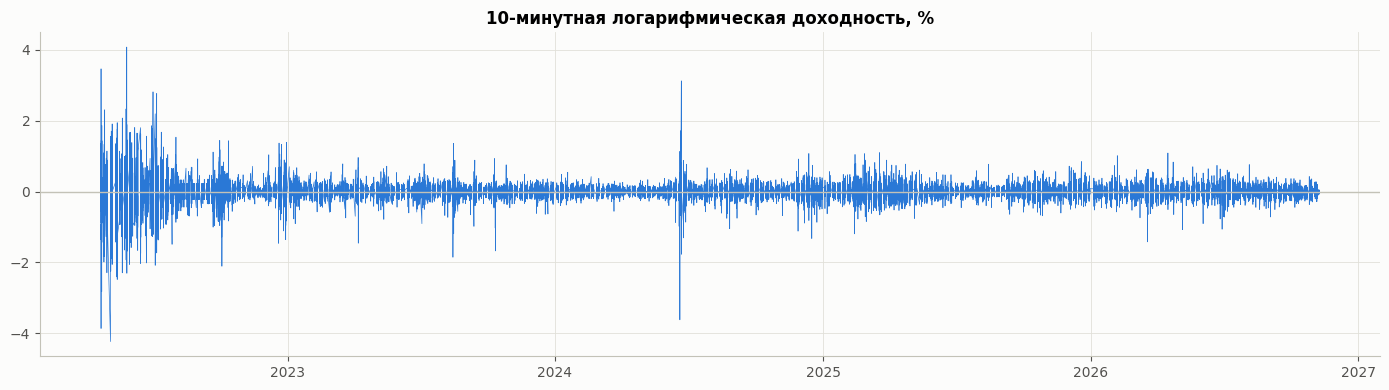

,ADF stat,ADF p-value,KPSS stat,KPSS p-value
ряд,,,,
rprice (уровень),-1.7468,0.407177,20.9812,0.01
log_return_ldp (доходность),-38.3757,0,0.199467,0.1


In [36]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(rolled_series["begin"], rolled_series["log_return_ldp"] * 100, color=PALETTE[0], linewidth=0.5)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("10-минутная логарифмическая доходность, %")
plt.tight_layout()
plt.show()

rprice_series = rolled_series["rprice"].dropna()
stat_rows = []
for name, series in [("rprice (уровень)", rprice_series), ("log_return_ldp (доходность)", returns)]:
    adf_res = adfuller(series, autolag="AIC")
    kpss_res = kpss(series, regression="c", nlags="auto")
    stat_rows.append({"ряд": name, "ADF stat": adf_res[0], "ADF p-value": adf_res[1],
                      "KPSS stat": kpss_res[0], "KPSS p-value": kpss_res[1]})
stationarity = pd.DataFrame(stat_rows).set_index("ряд")
stationarity

**Вывод по стационарности.** ADF и KPSS согласуются. Для индекса `rprice` ADF не отвергает единичный корень (p ≈ 0,41), KPSS отвергает стационарность (p < 0,01) → уровень цены нестационарен. Для `log_return_ldp` ADF отвергает единичный корень (p ≈ 0), KPSS не отвергает стационарность (p > 0,1) → доходности стационарны по уровню. Моделировать нужно доходности. При этом амплитуда колебаний доходности заметно меняется во времени (2022 г., июнь 2024 г.) — дисперсия непостоянна (см. 4.3).

*Примечание:* KPSS выдаёт p-value по таблице в диапазоне [0,01; 0,1], поэтому значения 0,01 и 0,1 означают «меньше» и «больше» соответственно.

### 4.3 Автокорреляция доходностей и кластеризация волатильности

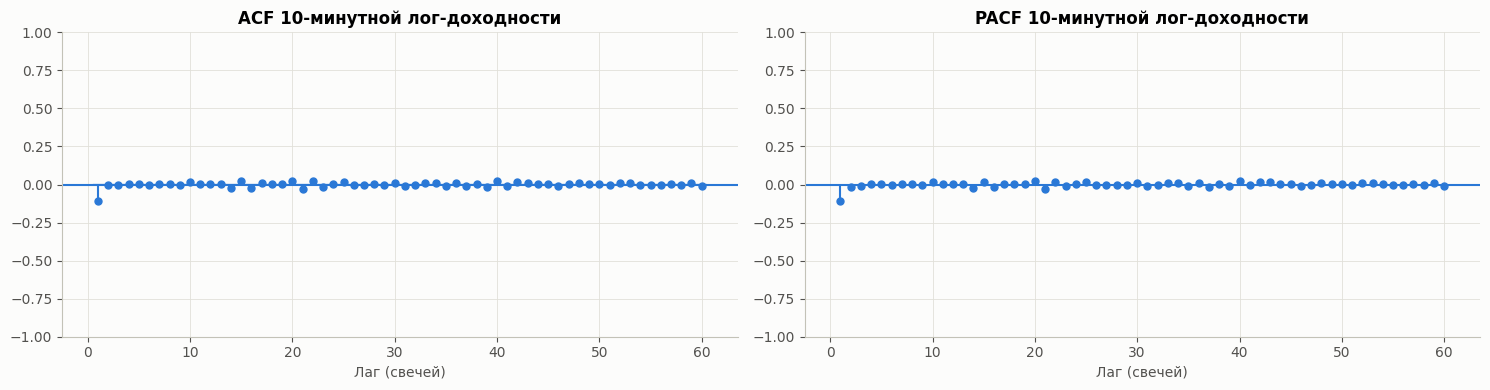

95%-граница значимости ACF: ± 0.0062


,lag,acf,pacf,acf_squared_returns
0,1,-0.106122,-0.106122,0.260646
1,2,-0.003497,-0.014927,0.172857
2,3,-0.00565638,-0.00770559,0.164389
3,4,0.00471952,0.0032746,0.11955
4,5,0.00107121,0.00183411,0.124629
5,6,-0.00050797,-0.000154866,0.107876
6,7,0.00546473,0.00553485,0.116477
7,8,0.00542089,0.00667028,0.129413
8,9,-0.00219206,-0.000815008,0.119929
9,10,0.0139884,0.0140092,0.123102


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(returns, lags=60, zero=False, ax=axes[0], color=PALETTE[0], vlines_kwargs={"colors": PALETTE[0]})
axes[0].set_title("ACF 10-минутной лог-доходности")
plot_pacf(returns, lags=60, zero=False, method="ywm", ax=axes[1], color=PALETTE[0], vlines_kwargs={"colors": PALETTE[0]})
axes[1].set_title("PACF 10-минутной лог-доходности")
for ax in axes:
    ax.set_xlabel("Лаг (свечей)")
plt.tight_layout()
plt.show()

squared_returns = returns ** 2
acf_pacf_table = pd.DataFrame({"lag": range(1, 21), "acf": acf(returns, nlags=20, fft=True)[1:],
                               "pacf": pacf(returns, nlags=20, method="ywm")[1:]})
squared_acf_table = pd.DataFrame({"lag": range(1, 21), "acf_squared_returns": acf(squared_returns, nlags=20, fft=True)[1:]})
print("95%-граница значимости ACF: ±", round(1.96 / np.sqrt(len(returns)), 4))
acf_pacf_table.merge(squared_acf_table, on="lag").head(10)

In [38]:
# Корреляция с лагом, заданным во времени (а не в строках): учитывает пропуски свечей
returns_time = rolled_series[["begin", "log_return_ldp"]].dropna().set_index("begin")["log_return_ldp"]
fixed_lag_rows = []
for lag_minutes in [10, 20, 30, 40, 50, 60]:
    lagged = returns_time.copy()
    lagged.index = lagged.index + pd.Timedelta(minutes=lag_minutes)
    aligned = pd.concat([returns_time.rename("current"), lagged.rename("lagged")], axis=1).dropna()
    fixed_lag_rows.append({"lag_minutes": lag_minutes, "correlation": aligned["current"].corr(aligned["lagged"]),
                           "n_pairs": len(aligned)})
fixed_lag_corr_df = pd.DataFrame(fixed_lag_rows)
display(fixed_lag_corr_df)

lb = pd.concat({"returns": acorr_ljungbox(returns, lags=[1, 10, 20]),
                "squared_returns": acorr_ljungbox(squared_returns, lags=[1, 10, 20])}, axis=1)
lb

,lag_minutes,correlation,n_pairs
0,10,-0.108385,98327
1,20,-0.00416667,97115
2,30,-0.00302802,95937
3,40,0.000171724,94744
4,50,0.00561926,93574
5,60,9.95342e-05,92400


returns              squared_returns          
    lb_stat    lb_pvalue         lb_stat lb_pvalue
1  1,133.39  1.8311e-248        6,837.03         0
10 1,166.36 2.59364e-244        22,760.5         0
20 1,368.75 5.53507e-278        34,591.2         0

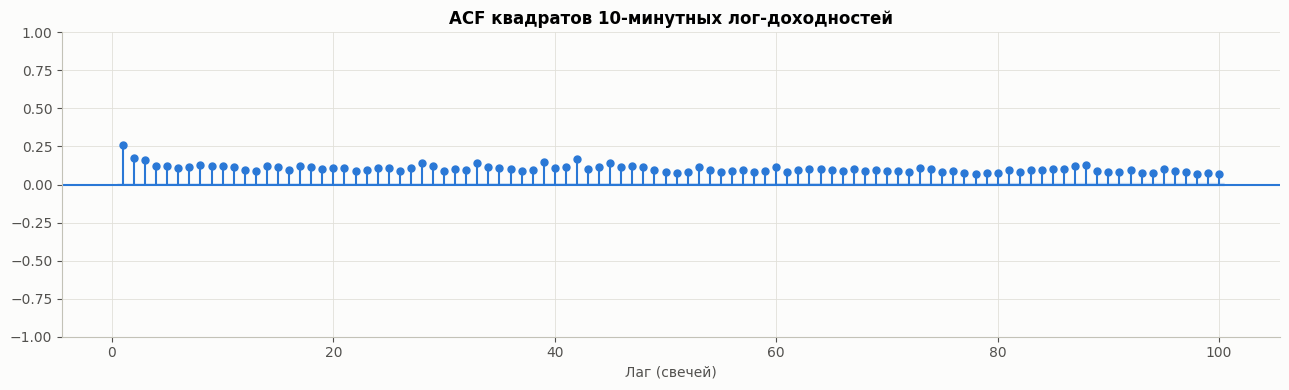

In [39]:
fig, ax = plt.subplots(figsize=(13, 4))
plot_acf(squared_returns, lags=100, zero=False, ax=ax, color=PALETTE[0], vlines_kwargs={"colors": PALETTE[0]})
ax.set_title("ACF квадратов 10-минутных лог-доходностей")
ax.set_xlabel("Лаг (свечей)")
plt.tight_layout()
plt.show()

In [40]:
# Устойчивость эффекта первого лага во времени: Пирсон (чувствителен к выбросам) и Спирмен (ранговая)
_next_ok = (rolled_series["begin"].shift(-1) - rolled_series["begin"]) == pd.Timedelta(minutes=10)
pairs = pd.DataFrame({"begin": rolled_series["begin"], "r_t": rolled_series["log_return_ldp"],
                      "r_next": rolled_series["log_return_ldp"].shift(-1).where(_next_ok)}).dropna()


def lag1_stats(g):
    return pd.Series({"n": len(g), "pearson": g["r_t"].corr(g["r_next"]),
                      "spearman": g["r_t"].corr(g["r_next"], method="spearman")})


acf1_by_period = pairs.groupby(pairs["begin"].dt.year)[["r_t", "r_next"]].apply(lag1_stats)
acf1_by_period.index = acf1_by_period.index.astype(str)
acf1_by_period.loc["вся выборка"] = lag1_stats(pairs)
acf1_by_period.loc["с 16.09.2022"] = lag1_stats(pairs[pairs["begin"] >= "2022-09-16"])
acf1_by_period

,n,pearson,spearman
begin,,,
2022,"12,471",-0.186196,-0.153796
2023,"21,660",-0.0156063,-0.0516827
2024,"21,148",0.014997,-0.0330976
2025,"21,752",-0.0332994,-0.0672895
2026,"21,296",-0.0153944,-0.049172
вся выборка,"98,327",-0.108385,-0.0687542
с 16.09.2022,"92,244",-0.0182242,-0.0532767


**Вывод по временной зависимости.**
- Формально линейная зависимость сосредоточена на первом лаге: ACF/PACF ≈ −0,106, с лагом ровно 10 минут ≈ −0,108; на горизонтах 20–60 минут |ρ| < 0,01 (на 100 тыс. наблюдений отдельные лаги формально значимы при границе ±0,006, но экономически пренебрежимы).
- **Однако эффект первого лага неустойчив во времени.** Корреляция Пирсона −0,11 почти целиком создаётся 2022 годом (≈ −0,19); с осени 2022 г. она ≈ −0,02, по годам — от −0,03 до +0,02. Ранговая корреляция (Спирмен) стабильнее: −0,03…−0,07 каждый год. Значит, слабая тенденция к развороту знака есть, но её величина мала и на 2023–2026 гг. почти не даёт выигрыша в MSE. Это согласуется с разделом 2.7: у ближайшего контракта после 2022 г. ACF(1) ≈ 0. Как это сказывается на прогнозе, показано в разделе 6.
- Квадраты доходностей автокоррелированы сильно и долго: ACF ≈ 0,26 на первом лаге и ≈ 0,1 даже на 20-м; тест Льюнга–Бокса отвергает отсутствие автокорреляции. Это **кластеризация волатильности**: прогнозировать величину движения (волатильность) существенно проще, чем его направление.
- Следствия: AR(1) — естественный интерпретируемый baseline, но обучать его нужно на релевантном периоде (без 2022 г.) или робастно. Для риска/волатильности — признаки прошлой волатильности (rolling std, |r|, r²) и модели класса GARCH/HAR.

## 5. Целевая переменная и признаки

`target_return_10m` — лог-доходность следующей свечи, **только если она начинается ровно через 10 минут**. Если следующая свеча позже (перерыв, нет сделок), target = NaN, чтобы не смешивать горизонты прогноза.

Доля соседних свечей ровно через 10 минут: 97.70%
Наблюдений с корректным target: 98327 (97.70%)


log_return_ldp        -0.102419
candle_body          -0.0924267
rolling_std_20d      -0.0123067
squared_return       -0.0101873
candle_range         -0.0068496
abs_return          -0.00464915
log_volume           0.00718109
target_return_10m             1
Name: target_return_10m, dtype: float64

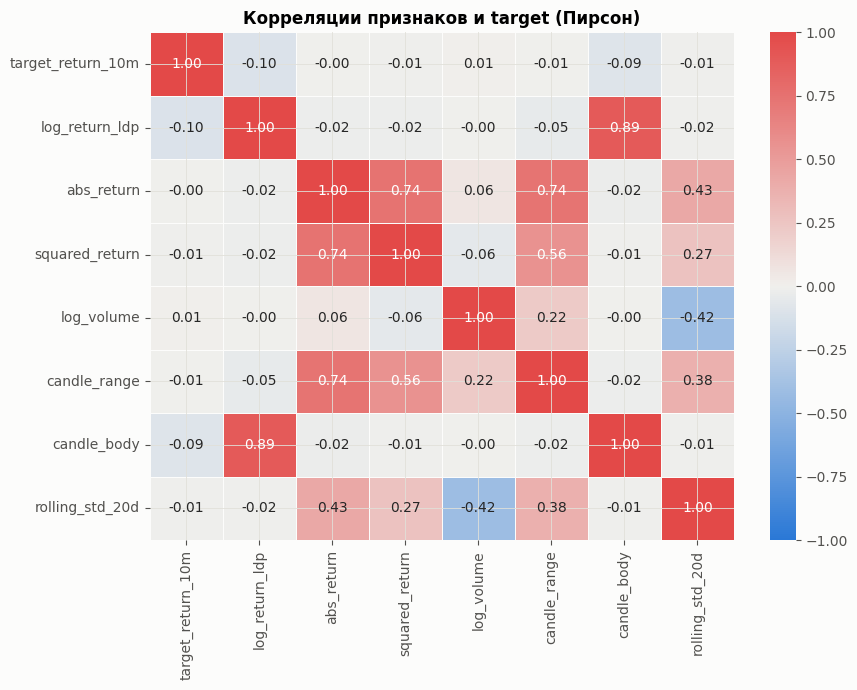

In [41]:
rolled_series["time_diff"] = rolled_series["begin"].diff()
rolled_series["next_time_diff"] = rolled_series["begin"].shift(-1) - rolled_series["begin"]
rolled_series["target_return_10m"] = np.where(rolled_series["next_time_diff"] == pd.Timedelta(minutes=10),
                                              rolled_series["log_return_ldp"].shift(-1), np.nan)
print(f"Доля соседних свечей ровно через 10 минут: {(rolled_series['time_diff'] == pd.Timedelta(minutes=10)).mean():.2%}")
print("Наблюдений с корректным target:", rolled_series["target_return_10m"].notna().sum(),
      f"({rolled_series['target_return_10m'].notna().mean():.2%})")

rolled_series["abs_return"] = rolled_series["log_return_ldp"].abs()
rolled_series["squared_return"] = rolled_series["log_return_ldp"] ** 2
rolled_series["candle_range"] = rolled_series["rolled_high"] - rolled_series["rolled_low"]
rolled_series["candle_body"] = rolled_series["rolled_close"] - rolled_series["rolled_open"]
rolled_series["log_volume"] = np.log1p(rolled_series["volume"])

feature_cols = ["log_return_ldp", "abs_return", "squared_return", "log_volume", "candle_range", "candle_body", "rolling_std_20d"]
eda_features = rolled_series[["begin", "target_return_10m"] + feature_cols].dropna().reset_index(drop=True)
target_correlations = eda_features.drop(columns="begin").corr()["target_return_10m"].sort_values()
display(target_correlations)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(eda_features.drop(columns="begin").corr(), annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, center=0,
            ax=ax, linewidths=0.5, linecolor="#fcfcfb")
ax.set_title("Корреляции признаков и target (Пирсон)")
plt.tight_layout()
plt.show()

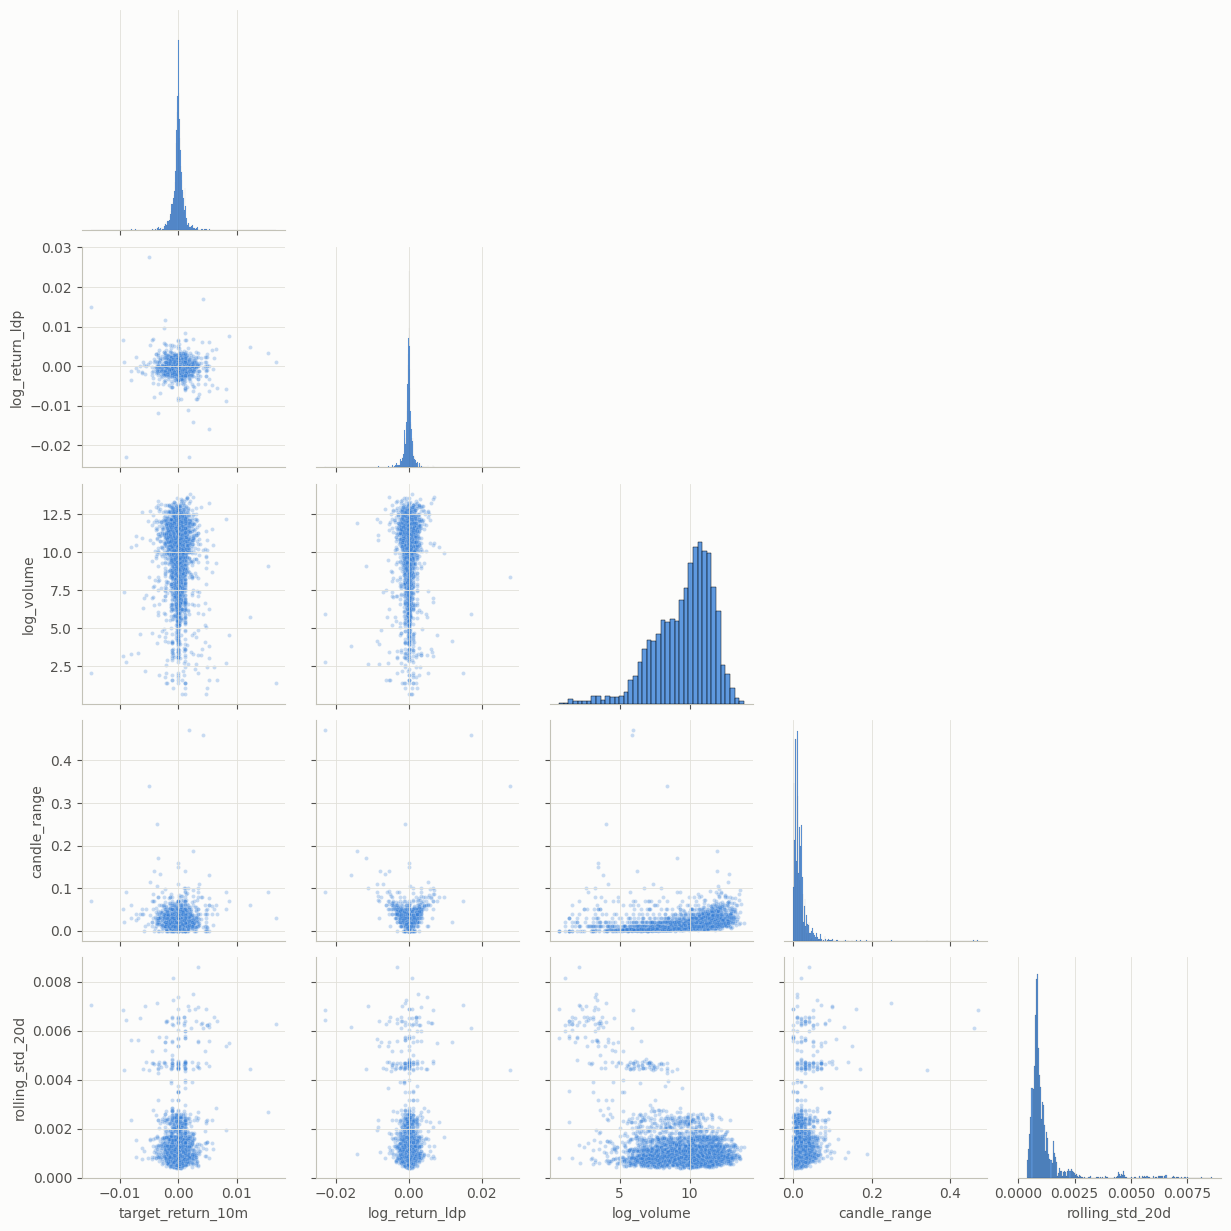

In [42]:
pairplot_sample = eda_features[["target_return_10m", "log_return_ldp", "log_volume", "candle_range", "rolling_std_20d"]].sample(5000, random_state=42)
sns.pairplot(pairplot_sample, corner=True, plot_kws={"alpha": 0.25, "s": 8, "color": PALETTE[0]},
             diag_kws={"color": PALETTE[0]})
plt.show()

**Вывод по признакам.**
- Корректный 10-минутный target есть у ≈ 97,7% наблюдений (98 327); остальное — перерывы в торгах и пропущенные свечи.
- Заметная линейная связь с будущей доходностью есть только у текущей доходности (≈ −0,10) и тела свечи (≈ −0,09) — это один и тот же эффект возврата к среднему (`corr(log_return, candle_body)` ≈ 0,89, признаки дублируют друг друга).
- Объём, диапазон свечи, |r|, r² и rolling std почти не коррелируют с **направлением** следующей доходности (|ρ| ≈ 0,01), но сильно связаны между собой и с **величиной** будущего движения (кластеризация волатильности) — они полезны для прогноза риска, масштабирования позиции и как условия для нелинейных моделей.
- Объём сильно скошен вправо → в моделях используем `log1p(volume)`.

## 6. Метрики качества и baseline (задания 4–5)

### 6.1 Выбор метрик

| Метрика | Зачем | Комментарий |
|---|---|---|
| **MAE** | Основная метрика точности | В единицах доходности, устойчива к тяжёлым хвостам |
| **RMSE** | Штраф за крупные промахи | Чувствительна к выбросам (excess kurtosis ≈ 75) |
| **R²_OOS** | Доля улучшения MSE относительно нулевого прогноза | $1 - \text{MSE}_{model}/\text{MSE}_{zero}$; > 0 — модель лучше «ничего не прогнозировать». Стандарт для прогноза доходностей |
| **Directional accuracy** | Угадан ли знак | Считается только где факт и прогноз ≠ 0; ≈ 50% — нет навыка |
| **Тест Диболда–Мариано** | Значимо ли отличие от baseline | Сравнение потерь модели и нулевого прогноза |
| **Метрики стратегии** | Есть ли экономический смысл | Доходность sign-стратегии **с учётом издержек** |

**От sMAPE и MAPE отказываемся:** target часто равен нулю (≈ 9% наблюдений) и почти всегда близок к нулю, знаменатель вырождается, значения 150–200% ничего не говорят о качестве. **MASE** сохранён для сопоставимости со старой версией, но интерпретировать его нужно осторожно: в знаменателе — ошибка наивного прогноза «следующая доходность = текущей», который для доходностей заведомо плох (он хуже нулевого прогноза), поэтому MASE ≈ 0,5 у нулевого прогноза **не означает** наличия навыка.

In [43]:
def dm_test(e_model, e_base):
    # Диболд–Мариано для квадратичных потерь, горизонт 1 шаг. Отрицательная статистика — модель лучше базы.
    d = e_model ** 2 - e_base ** 2
    if not np.any(d):
        return np.nan, np.nan
    dm = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    return dm, 2 * (1 - stats.norm.cdf(abs(dm)))


def calculate_metrics(y_true, y_pred, y_train_returns):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    naive_scale = np.mean(np.abs(np.diff(y_train_returns)))
    nz = (y_true != 0) & (y_pred != 0)
    dm, dm_p = dm_test(y_true - y_pred, y_true)
    return {"MAE": mae, "RMSE": np.sqrt(mse), "R2_OOS_%": (1 - mse / np.mean(y_true ** 2)) * 100,
            "MASE": mae / naive_scale,
            "DirAcc_%": (np.sign(y_true[nz]) == np.sign(y_pred[nz])).mean() * 100 if nz.any() else np.nan,
            "DM_vs_zero": dm, "DM_p": dm_p}

### 6.2 Baseline-модели

Хронологическое разбиение 80/20 (без перемешивания). Все модели — **одношаговые**: прогноз на t+1 строится по информации на момент t.

- **Zero** — доходность 0 (случайное блуждание; главный бенчмарк).
- **Train mean** — средняя доходность train.
- **Persistence** — следующая доходность равна текущей.
- **AR(1)** — $\hat r_{t+1} = a + b\,r_t$, коэффициенты по train (МНК); второй вариант обучен на train без весны–лета 2022 г.
- **Ridge** — линейная модель на признаках из раздела 5 (со стандартизацией).

*Исправление относительно прошлой версии:* раньше ARIMA(1,0,0) прогнозировалась через `forecast(steps=len(test))` — это прогноз на 19 тыс. шагов вперёд от конца train, который за пару шагов сходится к константе. Поэтому ARIMA и не отличалась от нулевого прогноза. Ниже AR(1) применяется корректно — к каждой текущей доходности теста.

In [44]:
split_time = eda_features["begin"].iloc[int(len(eda_features) * 0.8)]
train_data = eda_features[eda_features["begin"] < split_time].copy()
test_data = eda_features[eda_features["begin"] >= split_time].copy()
y_train, y_true = train_data["target_return_10m"].to_numpy(), test_data["target_return_10m"].to_numpy()
y_train_returns = train_data["log_return_ldp"].to_numpy()
print(f"Train: {len(train_data)} ({train_data['begin'].min():%Y-%m-%d} — {train_data['begin'].max():%Y-%m-%d})")
print(f"Test:  {len(test_data)} ({test_data['begin'].min():%Y-%m-%d} — {test_data['begin'].max():%Y-%m-%d})")
print(f"Доля нулевых target в тесте: {(y_true == 0).mean():.1%}")

ar1 = LinearRegression().fit(train_data[["log_return_ldp"]], y_train)
train_post = train_data[train_data["begin"] >= "2022-09-16"]
ar1_post = LinearRegression().fit(train_post[["log_return_ldp"]], train_post["target_return_10m"])
print(f"AR(1), весь train:        a = {ar1.intercept_:.2e}, b = {ar1.coef_[0]:.4f}")
print(f"AR(1), train с 16.09.2022: a = {ar1_post.intercept_:.2e}, b = {ar1_post.coef_[0]:.4f}")

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(train_data[feature_cols], y_train)

predictions = {
    "Zero": np.zeros_like(y_true),
    "Train mean": np.full_like(y_true, y_train.mean()),
    "Persistence": test_data["log_return_ldp"].to_numpy(),
    "AR(1)": ar1.predict(test_data[["log_return_ldp"]]),
    "AR(1), train с 16.09.2022": ar1_post.predict(test_data[["log_return_ldp"]]),
    "Ridge (признаки разд. 5)": ridge.predict(test_data[feature_cols]),
}
results_df = pd.DataFrame({name: calculate_metrics(y_true, pred, y_train_returns) for name, pred in predictions.items()}).T
results_df

Train: 78589 (2022-04-25 — 2026-01-30)
Test:  19648 (2026-01-30 — 2026-11-08)
Доля нулевых target в тесте: 8.1%
AR(1), весь train:        a = -8.82e-06, b = -0.1066
AR(1), train с 16.09.2022: a = -4.29e-06, b = -0.0180


,MAE,RMSE,R2_OOS_%,MASE,DirAcc_%,DM_vs_zero,DM_p
Zero,0.000573819,0.000904787,0,0.507753,NaN,NaN,NaN
Train mean,0.000574535,0.000904853,-0.014433,0.508386,49.6121,1.13149,0.25785
Persistence,0.000851328,0.00129279,-104.156,0.753311,46.7227,24.9639,0
AR(1),0.000574491,0.000908401,-0.800378,0.508347,52.6596,3.07266,0.00212161
"AR(1), train с 16.09.2022",0.000573725,0.000904685,0.0227094,0.507669,51.8949,-0.505248,0.613385
Ridge (признаки разд. 5),0.000574625,0.000908527,-0.828307,0.508466,52.654,3.04366,0.00233718


### 6.3 Предварительные ML-эксперименты (нелинейные модели)

Добавлены лаги доходности и объёма (лаги считаются **по полному ряду до фильтрации** и обнуляются, если между свечами не 10 минут), календарные признаки и технические индикаторы на **roll-скорректированной** цене (в прошлой версии MA и RSI считались по сырой `close` и «перепрыгивали» через roll gaps).

In [45]:
fs = rolled_series.copy()
step_ok = fs["time_diff"] == pd.Timedelta(minutes=10)
for lag in [1, 2, 3]:
    ok = step_ok.rolling(lag + 1, min_periods=lag + 1).sum() == lag + 1      # цепочка из регулярных шагов
    fs[f"return_lag_{lag}"] = fs["log_return_ldp"].shift(lag).where(ok)
    fs[f"log_volume_lag_{lag}"] = fs["log_volume"].shift(lag).where(ok)
fs["hour"] = fs["begin"].dt.hour
fs["dayofweek"] = fs["begin"].dt.dayofweek
fs["evening_session"] = (fs["hour"] >= 19).astype(int)
fs["ma_diff"] = fs["rolled_close"].rolling(10).mean() - fs["rolled_close"].rolling(30).mean()
fs["volatility_20"] = fs["log_return_ldp"].rolling(20).std()
delta = fs["rolled_close"].diff()
gain, loss = delta.clip(lower=0).rolling(14).mean(), (-delta.clip(upper=0)).rolling(14).mean()
fs["rsi_14"] = 100 - 100 / (1 + gain / loss.replace(0, np.nan))

features_ml = feature_cols + ["return_lag_1", "return_lag_2", "return_lag_3", "log_volume_lag_1", "log_volume_lag_2",
                              "hour", "dayofweek", "evening_session", "ma_diff", "volatility_20", "rsi_14"]
ml_df = fs[["begin", "target_return_10m", "log_return_ldp"] + [c for c in features_ml if c != "log_return_ldp"]].dropna(
    subset=["target_return_10m", "rolling_std_20d"]).reset_index(drop=True)
train_ml, test_ml = ml_df[ml_df["begin"] < split_time], ml_df[ml_df["begin"] >= split_time]
print("Train:", len(train_ml), "| Test:", len(test_ml), "| признаков:", len(features_ml))

hgb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, loss="absolute_error",
                                    random_state=42).fit(train_ml[features_ml], train_ml["target_return_10m"])
rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=200, random_state=42, n_jobs=-1).fit(
    train_ml[features_ml].fillna(0), train_ml["target_return_10m"])

y_true_ml = test_ml["target_return_10m"].to_numpy()
ml_predictions = {
    "Zero": np.zeros_like(y_true_ml),
    "AR(1)": ar1.predict(test_ml[["log_return_ldp"]]),
    "Random Forest": rf.predict(test_ml[features_ml].fillna(0)),
    "HistGB (MAE loss)": hgb.predict(test_ml[features_ml]),
}
ml_results = pd.DataFrame({n: calculate_metrics(y_true_ml, p, train_ml["log_return_ldp"].to_numpy())
                           for n, p in ml_predictions.items()}).T
ml_results

Train: 78589 | Test: 19648 | признаков: 18


,MAE,RMSE,R2_OOS_%,MASE,DirAcc_%,DM_vs_zero,DM_p
Zero,0.000573819,0.000904787,0,0.507753,NaN,NaN,NaN
AR(1),0.000574491,0.000908401,-0.800378,0.508347,52.6596,3.07266,0.00212161
Random Forest,0.000574547,0.000906578,-0.396252,0.508397,50.9198,1.64436,0.100101
HistGB (MAE loss),0.000573671,0.000904535,0.0557799,0.507622,53.8171,-1.42369,0.154537


In [46]:
# Кросс-валидация по времени (expanding window): сравниваем HistGB с нулевым прогнозом и AR(1) на каждом фолде
tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []
for fold, (tr, te) in enumerate(tscv.split(ml_df), start=1):
    tr_df, te_df = ml_df.iloc[tr], ml_df.iloc[te]
    yt = te_df["target_return_10m"].to_numpy()
    model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, loss="absolute_error",
                                          random_state=42).fit(tr_df[features_ml], tr_df["target_return_10m"])
    ar = LinearRegression().fit(tr_df[["log_return_ldp"]], tr_df["target_return_10m"])
    cv_rows.append({"fold": fold, "test_start": te_df["begin"].min().date(),
                    "MAE_zero": np.abs(yt).mean(),
                    "MAE_AR1": mean_absolute_error(yt, ar.predict(te_df[["log_return_ldp"]])),
                    "MAE_HistGB": mean_absolute_error(yt, model.predict(te_df[features_ml])),
                    "R2_OOS_AR1_%": (1 - mean_squared_error(yt, ar.predict(te_df[["log_return_ldp"]])) / np.mean(yt ** 2)) * 100})
cv_df = pd.DataFrame(cv_rows)
cv_df

,fold,test_start,MAE_zero,MAE_AR1,MAE_HistGB,R2_OOS_AR1_%
0,1,2023-03-10,0.000585533,0.000590124,0.000585632,-2.62257
1,2,2023-12-08,0.000504061,0.000508087,0.000505129,-2.4461
2,3,2024-09-16,0.000747532,0.000748962,0.000747481,-1.2561
3,4,2025-06-26,0.000573837,0.000574128,0.000573809,-0.900921
4,5,2026-03-27,0.000559312,0.000559749,0.000558736,-0.711061


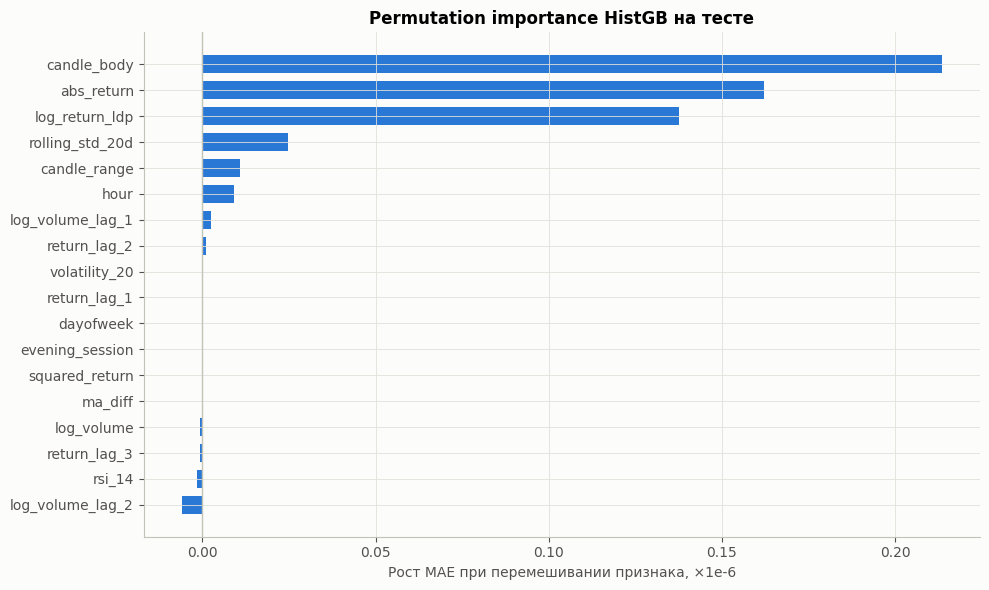

In [47]:
# Важность признаков: permutation importance на тесте (рост MAE при перемешивании признака)
perm = permutation_importance(hgb, test_ml[features_ml], y_true_ml, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=features_ml).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importance.index, importance.values * 1e6, color=PALETTE[0], height=0.7)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Permutation importance HistGB на тесте")
ax.set_xlabel("Рост MAE при перемешивании признака, ×1e-6")
plt.tight_layout()
plt.show()

### 6.4 Экономическая проверка: sign-стратегия с учётом издержек

Позиция = знак прогноза (+1 / −1 / 0). Издержки: 1 шаг цены (0,001 руб.) на каждое изменение позиции на 1 контракт, т. е. ≈ 0,8 б.п. при цене 12 руб. Это **оптимистичная** оценка (без биржевой комиссии и проскальзывания).

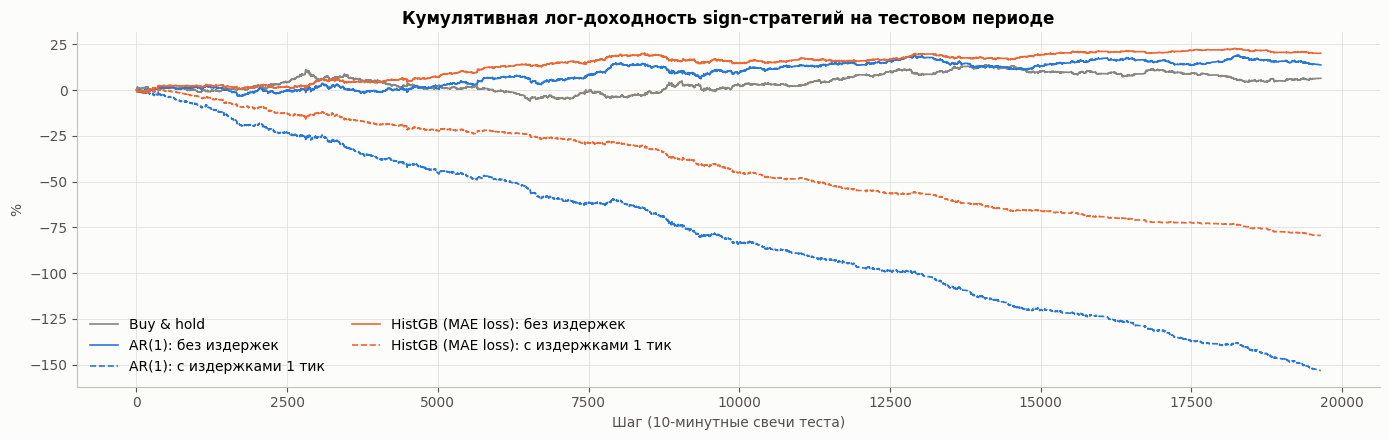

,gross_%,net_%,avg_turnover
strategy,,,
AR(1),13.716,-153.211,0.999949
HistGB (MAE loss),20.067,-79.3849,0.592834


In [48]:
price_test = rolled_series.set_index("begin").loc[test_ml["begin"], "close"].to_numpy()
cost_per_unit = 0.001 / price_test


def strategy_curve(pred, y, cost):
    position = np.sign(pred)
    turnover = np.abs(np.diff(np.r_[0, position]))
    gross = position * y
    return np.cumsum(gross), np.cumsum(gross - turnover * cost), turnover.mean()


fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(np.cumsum(y_true_ml) * 100, color=MUTED, linewidth=1.2, label="Buy & hold")
summary = []
for (name, pred), color in zip([("AR(1)", ml_predictions["AR(1)"]), ("HistGB (MAE loss)", ml_predictions["HistGB (MAE loss)"])],
                               [PALETTE[0], PALETTE[1]]):
    gross, net, turnover = strategy_curve(pred, y_true_ml, cost_per_unit)
    ax.plot(gross * 100, color=color, linewidth=1.2, label=f"{name}: без издержек")
    ax.plot(net * 100, color=color, linewidth=1.2, linestyle="--", label=f"{name}: с издержками 1 тик")
    summary.append({"strategy": name, "gross_%": gross[-1] * 100, "net_%": net[-1] * 100, "avg_turnover": turnover})
ax.set_title("Кумулятивная лог-доходность sign-стратегий на тестовом периоде")
ax.set_xlabel("Шаг (10-минутные свечи теста)")
ax.set_ylabel("%")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout()
plt.show()
pd.DataFrame(summary).set_index("strategy")

**Вывод по метрикам и baseline.**
- **Главный бенчмарк — нулевой прогноз, и его не побеждает ни одна модель.** Тест: 30.01–08.11.2026, 19,6 тыс. наблюдений. Отличия MAE между моделями — в 4–5 знаке после запятой.
- **Persistence** — худшая модель (MAE в 1,5 раза выше, R²_OOS ≈ −104%): «повторять последнее движение» на доходностях бессмысленно.
- **AR(1), обученная на всей истории, хуже нулевого прогноза** (R²_OOS ≈ −0,8%, DM-тест значим *против* модели), хотя знак угадывает в 52,7% случаев. Причина — 2022 год: коэффициент b ≈ −0,107 выучен на режиме с сильным разворотом, а в 2023–2026 гг. эффект в разы слабее (раздел 4.3). На кросс-валидации AR(1) проигрывает нулевому прогнозу на всех 5 фолдах. AR(1), обученная без 2022 г., даёт почти нулевые прогнозы и практически совпадает с нулевым прогнозом.
- **Ridge, Random Forest, HistGB** с расширенным набором признаков статистически значимо нулевой прогноз не превосходят; у лучшей (HistGB с MAE-loss) R²_OOS ≈ +0,06% (DM p ≈ 0,15) при directional accuracy ≈ 54%. По permutation importance наибольший вклад у тела свечи, |r| и текущей доходности, но даже он меньше 0,05% от MAE. Технические индикаторы (MA, RSI), лаги 2–3 и календарь в прогнозе направления практически не участвуют.
- Экономически: sign-стратегии по AR(1) и HistGB прибыльны только без издержек. Они меняют позицию почти на каждой свече (AR(1) — практически всегда), и даже 1 тик издержек **превращает доходность в большой убыток**.
- **Рекомендуемый набор для дальнейших экспериментов:** baseline = Zero (основной) + AR(1) (интерпретируемый) + Persistence (нижняя граница); метрики = MAE, RMSE, R²_OOS, directional accuracy, DM-тест против Zero + доходность стратегии с издержками. sMAPE/MAPE не использовать. Любая новая модель имеет смысл, только если она значимо лучше Zero по DM-тесту на walk-forward-валидации.

## 7. Итоговые выводы и рекомендации

**Данные.** 19 квартальных контрактов `CR` (апрель 2022 — ноябрь 2026), 247 тыс. 10-минутных свечей. Данные чистые (нет пропусков значений, дублей, ошибок OHLC), поле `value` ≡ 0. Сетка времени нерегулярна из-за отсутствия сделок — в основном в дальних контрактах и в 2022 г.; у ближайшего контракта ≈ 99% шагов ровно 10 минут.

**EDA по контрактам (п. 1).**
1. Ликвидность сосредоточена в ближайшем контракте (93,5% дневного объёма серии) и в последнем квартале жизни контракта (≈ 92–94% его объёма). Дальние контракты — редкие сделки и шумные цены.
2. С конца 2022 г. ликвидность переходит на следующий контракт в последние 1–2 дня перед экспирацией (в 2022 г. — на 2–8 дней раньше). Правило переключения «по экспирации» в целом обосновано.
3. Устойчивое контанго (1,4–3,7% за квартал, ≈ 6–15% годовых) — процентная составляющая, отражающая разницу ставок по рублю и юаню. Отсюда roll gaps при склейке.
4. Тяжёлые хвосты и кластеризация волатильности есть во всех контрактах. Отрицательный AR(1) — только в дальних контрактах (bid-ask bounce) и в 2022 г.; 2022 г. — отдельный высоковолатильный режим.
5. Сильная внутридневная сезонность: пик активности в 10:00, тихие вечерняя и выходные сессии.

**Единый ряд и доходности (пп. 2–3).** Построены три варианта: front-contract, back-adjusted (`rolled_*`) и индекс López de Prado (`rprice`). Roll gaps (18 шт., в среднем +2,5%) устранены. Лог-доходности стационарны (ADF + KPSS), уровень цены — нет. Распределение доходностей далеко от нормального (excess kurtosis ≈ 75; без 2022 г. — ≈ 46). Выбросы связаны с высоким, а не низким объёмом и не удаляются. Направление: ACF(1) ≈ −0,11 на всей выборке, но лишь ≈ −0,02 с осени 2022 г. Волатильность: сильная и долгая автокорреляция квадратов доходностей.

**Метрики и baseline (пп. 4–5).** Основные метрики — MAE, RMSE, R²_OOS, directional accuracy, DM-тест; sMAPE исключён. Ошибка старой версии исправлена: ARIMA прогнозировалась на весь тест сразу, поэтому совпадала с константой. Бенчмарки — нулевой прогноз и одношаговая AR(1). На 10-минутном горизонте **ни одна модель значимо не превосходит нулевой прогноз**: AR(1) из-за режима 2022 г. даже хуже. С учётом издержек сигнал направления на 10 минутах неторгуем.

**Рекомендации для следующих этапов**
- Добавить варианты единого ряда: переключение в начале дня экспирации / по объёму; не терять свечи нового контракта после 14:00 дня экспирации (≈ 56 на переход).
- Обучать модели без весны–лета 2022 г. (или с весами по времени) и всегда сравнивать с Zero по DM-тесту.
- Увеличить горизонт прогноза (1 час, конец сессии, 1 день) и/или прогнозировать волатильность (HAR, GARCH, ML на |r|) — там сигнал сильнее.
- Добавлять признаки сессии/часа, прошлой волатильности, контанго (спред ближайшего и следующего контракта), признаки внешних рынков (USD/RUB, CNY/RUB TOM, ставки).
- Оценивать торговые сигналы только с учётом издержек и только при хронологической валидации (walk-forward).

## 8. Сохранение результатов

In [49]:
front_series.to_csv(PROCESSED_DIR / "cnyrub_front_contract_10m.csv", index=False)
rolled_series.drop(columns=["value"]).to_csv(PROCESSED_DIR / "cnyrub_futures_EDA_final.csv", index=False)

passport.to_csv(RESULTS_DIR / "contracts_passport.csv")
quality.to_csv(RESULTS_DIR / "contracts_quality.csv")
gap_table.to_csv(RESULTS_DIR / "contracts_gaps.csv")
ret_stats_nearest.to_csv(RESULTS_DIR / "contracts_return_stats.csv")
handover_df.to_csv(RESULTS_DIR / "liquidity_handover.csv", index=False)
sync_roll_gaps_df.to_csv(RESULTS_DIR / "roll_gaps.csv", index=False)
target_correlations.to_csv(RESULTS_DIR / "target_correlations.csv")
acf_pacf_table.to_csv(RESULTS_DIR / "acf_pacf_returns.csv", index=False)
squared_acf_table.to_csv(RESULTS_DIR / "acf_squared_returns.csv", index=False)
outlier_rate_by_volume.to_csv(RESULTS_DIR / "outlier_rate_by_volume.csv")
results_df.to_csv(RESULTS_DIR / "baseline_metrics.csv")
ml_results.to_csv(RESULTS_DIR / "ml_metrics.csv")

print("Сохранено:", sorted(p.name for p in PROCESSED_DIR.iterdir()) + sorted(p.name for p in RESULTS_DIR.iterdir()))
print("Финальный датасет:", rolled_series.shape)

Сохранено: ['cnyrub_front_contract_10m.csv', 'cnyrub_futures_EDA_final.csv', 'acf_pacf_returns.csv', 'acf_squared_returns.csv', 'baseline_metrics.csv', 'contracts_gaps.csv', 'contracts_passport.csv', 'contracts_quality.csv', 'contracts_return_stats.csv', 'liquidity_handover.csv', 'ml_metrics.csv', 'outlier_rate_by_volume.csv', 'roll_gaps.csv', 'target_correlations.csv']
Финальный датасет: (100637, 28)
